# Proliferation and early organoid shape
Dataset: **20250929**. Organoid-level distributions use one observation per preprocessed cell graph.
Titles distinguish **global (whole organoid)** counts/fractions from **regional** counts/fractions within each assigned Crypt, Neck or Villus region. All sphericity figures are global, including their secretory-status classification. No-crypt reference panels are also global. The stacked bars report fractions of crypts, with marker status determined within the crypt region, not cell fractions.

- Proliferating cells are positive for **Cyclin A OR Cyclin D**, counted once even if both are positive.
- Only the saved, processed `markers_bin` field is used. Raw marker backups are never used and no further exclusivity rules are applied.
- Cell number is the number of graph nodes (cells retained during preprocessing/projection), not necessarily the number of nuclei in the original cell table.
- Sphericity is $\Psi=\pi^{1/3}(6V)^{2/3}/A$, where $A$ and $V$ are the surface area and enclosed volume of the linked mesh. A sphere has sphericity 1. No additional geometric smoothing is applied.
- Geometry is loaded in original file coordinates, assumed to be micrometers; no graph coordinate normalization is applied. Volume is reported in $\mu\mathrm{m}^3$.
- A positive Lysozyme/Serotonin status means **at least one Lysozyme-positive OR Serotonin-positive cell** anywhere in the organoid; it does not require coexpression.
- Invalid or missing meshes are reported and excluded from geometry plots only. Valid graph counts remain in the exported per-organoid table. Dataset blacklist exclusions are reported separately.

TA cells are Cyclin A-or-D positive and negative for **every other measured marker** in the processed graph. TA fractions use all cells in the respective organoid or region as denominator, not just proliferating cells.


In [1]:
from pathlib import Path
import sys
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "src/organograph").is_dir())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from organograph.graph.io import load_cell_graph
from organograph.graph.access import graph_marker_index
from organograph.mesh.OrganoidMesh import OrganoidMesh
from organograph.io_utils.blacklist import load_optional_blacklist, default_discard_labels_path

DATASET = "20250929"
DATASET_ROOT = PROJECT_ROOT.parent / "NicoleData" / DATASET
GRAPH_DIR = DATASET_ROOT / "graphs_preprocessed"
SELECTED_TIMEPOINTS = ['day1p5', 'day2', 'day2p5', 'day3', 'day3p5', 'day4']
SECRETORY_FIGURE_TIMEPOINTS = ['day3', 'day3p5', 'day4']
DEVIATION_SCATTER_TIMEPOINTS = ['day3', 'day3p5', 'day4']
SCATTER_ELLIPSE_N_STD = 1.0  # Covariance radius in (fraction, log10 deviation), not a confidence interval.
MIN_CELLS = 20  # Inclusive minimum graph node count, applied to all analyses.
SPHERICAL_MIN = 0.98  # Inclusive lower bound for spherical organoids.
NEAR_SPHERICAL_MIN = 0.92  # Inclusive; upper bound is SPHERICAL_MIN (exclusive).
NEAR_SPHERICAL_SPLIT = 0.95  # Split the near-spherical interval into two groups.
SHAPE_CATEGORY_ORDER = ['Non-spherical', 'Near-spherical (lower)', 'Near-spherical (upper)', 'Spherical']
SHAPE_COLORS = dict(zip(SHAPE_CATEGORY_ORDER, ['#CC6677', '#DDCC77', '#44AA99', '#4477AA']))
TIMEPOINT_ALIASES = {"day4p5-more": "day4p5"}
BLACKLIST_PATH = default_discard_labels_path(DATASET_ROOT)  # Set None to disable.
MESH_COORD_TO_UM = 1.0  # Mesh files already store micrometers.
EXPORT = True
EXPORT_DIR = PROJECT_ROOT / "exports" / "proliferation_symmetry_breaking" / DATASET

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})


In [2]:
def summarize_processed_markers(graph):
    """Count the saved processed marker calls, without fallback to raw backups."""
    names = list(graph.graph.get("marker_names", []))
    required = ["Cyclin A", "Cyclin D", "Lysozyme", "Serotonin"]
    indices = {name: graph_marker_index(graph, name) for name in required}
    n_cells = graph.number_of_nodes()
    if n_cells == 0:
        raise ValueError("Empty graph: proliferation fraction is undefined.")
    values = np.asarray([attrs["markers_bin"] for _, attrs in graph.nodes(data=True)], dtype=float)
    if values.shape != (n_cells, len(names)):
        raise ValueError("Processed marker matrix does not match node count / marker names.")
    if not np.isfinite(values).all():
        raise ValueError("Required processed marker calls contain non-finite values.")
    positive = values > 0
    cyclin_a = positive[:, indices["Cyclin A"]]
    cyclin_d = positive[:, indices["Cyclin D"]]
    lysozyme = positive[:, indices["Lysozyme"]]
    serotonin = positive[:, indices["Serotonin"]]
    proliferating = cyclin_a | cyclin_d
    other_indices = [i for i, name in enumerate(names) if name not in {'Cyclin A', 'Cyclin D'}]
    ta = proliferating & ~positive[:, other_indices].any(axis=1)
    n_proliferating = int(proliferating.sum())
    return dict(n_cells=n_cells, n_cyclin_a_positive=int(cyclin_a.sum()),
                n_cyclin_d_positive=int(cyclin_d.sum()),
                n_cyclin_a_and_d_positive=int((cyclin_a & cyclin_d).sum()),
                n_proliferating=n_proliferating,
                fraction_proliferating=n_proliferating / n_cells,
                n_ta=int(ta.sum()), fraction_ta=float(ta.mean()),
                n_lysozyme_positive=int(lysozyme.sum()),
                n_serotonin_positive=int(serotonin.sum()),
                has_lysozyme_or_serotonin=bool(lysozyme.any() or serotonin.any()),
                marker_field="markers_bin",
                marker_postprocess_steps=json.dumps(graph.graph.get("marker_postprocess_steps", [])))


def resolve_mesh_path(graph, dataset_root):
    stored = graph.graph.get("mesh_path")
    if not stored:
        raise FileNotFoundError("No mesh_path in graph metadata.")
    path = Path(stored)
    if path.is_file():
        return path
    # Relocate a saved absolute path when the dataset has moved.
    if "fractal_output" in path.parts:
        index = path.parts.index("fractal_output")
        relocated = Path(dataset_root).joinpath(*path.parts[index:])
        if relocated.is_file():
            return relocated
    raise FileNotFoundError(f"Mesh not found: {path}")


def measure_mesh_geometry(mesh, coord_to_um=1.0):
    """Use the original surface, checking closure and coherent face orientation."""
    if not np.isfinite(coord_to_um) or coord_to_um <= 0:
        raise ValueError("Coordinate conversion must be finite and positive.")
    vertices = np.asarray(mesh.v, dtype=float)
    faces = np.asarray(mesh.f, dtype=np.int64)
    if vertices.ndim != 2 or vertices.shape[1] != 3 or not np.isfinite(vertices).all():
        raise ValueError("Invalid mesh vertices.")
    if faces.ndim != 2 or faces.shape[1] != 3 or not len(faces):
        raise ValueError("No triangular surface.")
    if faces.min() < 0 or faces.max() >= len(vertices):
        raise ValueError("Face index outside vertex array.")
    edges = np.concatenate([faces[:, [0, 1]], faces[:, [1, 2]], faces[:, [2, 0]]])
    _, inverse, counts = np.unique(np.sort(edges, axis=1), axis=0,
                                   return_inverse=True, return_counts=True)
    if np.any(counts != 2):
        raise ValueError("Mesh is not closed/manifold: an edge has other than two incident faces.")
    directions = np.where(edges[:, 0] < edges[:, 1], 1, -1)
    if np.any(np.bincount(inverse, weights=directions) != 0):
        raise ValueError("Mesh faces have inconsistent orientation.")
    # Centering improves signed-volume precision; no scale normalization or smoothing.
    mesh.v = (vertices - vertices.mean(axis=0)) * coord_to_um
    area = float(np.sum(mesh.face_areas()))
    volume = float(mesh.volume())
    if not np.isfinite(area) or not np.isfinite(volume) or area <= 0 or volume <= 0:
        raise ValueError("Non-positive/non-finite surface area or enclosed volume.")
    sphericity = float(np.cbrt(np.pi) * (6.0 * volume) ** (2.0 / 3.0) / area)
    if sphericity > 1.0 + 1e-6:
        raise ValueError(f"Sphericity exceeds 1 ({sphericity:.6g}); inspect mesh.")
    return dict(surface_area_um2=area, volume_um3=volume, sphericity=sphericity)


def classify_sphericity(values, near_min, near_split, spherical_min):
    if not (0 < near_min < near_split < spherical_min <= 1):
        raise ValueError('Require 0 < NEAR_SPHERICAL_MIN < NEAR_SPHERICAL_SPLIT < SPHERICAL_MIN <= 1.')
    values = np.asarray(values, dtype=float)
    categories = np.full(values.shape, None, dtype=object)
    finite = np.isfinite(values)
    categories[finite & (values < near_min)] = 'Non-spherical'
    categories[finite & (values >= near_min) & (values < near_split)] = 'Near-spherical (lower)'
    categories[finite & (values >= near_split) & (values < spherical_min)] = 'Near-spherical (upper)'
    categories[finite & (values >= spherical_min)] = 'Spherical'
    return categories


def timepoint_sort_key(name):
    match = re.match(r"day(\d+)(?:p(\d+))?", name)
    day = float(match[1] + ("." + match[2] if match[2] else "")) if match else np.inf
    return day, name


def add_marker_status_columns(table):
    result = table.copy()
    lysozyme = result.n_lysozyme_positive > 0
    serotonin = result.n_serotonin_positive > 0
    result['has_lysozyme_only'] = lysozyme & ~serotonin
    result['has_serotonin_only'] = serotonin & ~lysozyme
    result['has_lysozyme_or_serotonin'] = lysozyme | serotonin
    return result


def draw_half_violin(ax, values, position, side, color, width=0.38):
    """Width-normalized half density with median (solid) and quartiles (dashed)."""
    if side not in ('left', 'right'):
        raise ValueError("side must be 'left' or 'right'")
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    stats = dict(n_finite_values=len(values), mean=np.nan, median=np.nan,
                 q1=np.nan, q3=np.nan, minimum=np.nan, maximum=np.nan)
    if not len(values):
        return stats
    q1, median, q3 = np.quantile(values, [0.25, 0.5, 0.75])
    stats.update(mean=float(values.mean()), median=float(median), q1=float(q1),
                 q3=float(q3), minimum=float(values.min()), maximum=float(values.max()))
    direction = -1 if side == 'left' else 1
    if len(values) > 1 and np.ptp(values) > 0:
        violin = ax.violinplot([values], positions=[position], widths=2 * width,
                              showmeans=False, showmedians=False, showextrema=False,
                              bw_method='scott', points=100)
        body = violin['bodies'][0]
        vertices = body.get_paths()[0].vertices
        vertices[:, 0] = (np.minimum(vertices[:, 0], position) if side == 'left'
                          else np.maximum(vertices[:, 0], position))
        body.set_facecolor(color)
        body.set_edgecolor(color)
        body.set_alpha(0.65)
    else:
        # A single or constant observation has no estimable density.
        ax.plot([position, position + direction * width], [median, median],
                color=color, linewidth=5, alpha=0.65)
    for value, style, thickness in [(q1, '--', 1), (q3, '--', 1), (median, '-', 1.8)]:
        ax.plot([position + direction * width * 0.08, position + direction * width * 0.8],
                [value, value], color='black', linestyle=style, linewidth=thickness)
    return stats


# Regional proliferation and crypt-status comparisons
This section is independent of the sphericity analysis and uses the **20250929 preprocessed graphs** plus their saved `crypt_segmentations_graph` files.
Run the main configuration and shared marker/plot helper cells above, then this section; the mesh/sphericity calculations are not required.
The minimum of 20 graph cells and the dataset blacklist still apply, but the earlier timepoint selection does not.
The stacked bars and crypt-villus scatter include day3p5, day4 and day4p5; the day4p5 group pools day4p5 and day4p5-more, retaining the original folder in source_timepoint. Regional violin figures remain restricted to REGION_TIMEPOINTS (day3p5 and day4).

Crypt categories use $BI=[C(s_*)-C(1)]/C_{\max}$ with $s_*=0.75$ and the current `plot_crypt_compositions.ipynb` thresholds: bulged below -0.05, weakly budded from -0.05 through +0.05 (inclusive), fully budded above +0.05.
Circumferences at $s_*$ and 1 are linearly interpolated; $C_{\max}$ is the maximum finite sampled circumference at $s\leq1$.
No additional marker exclusivity or marker-based crypt filtering is applied.

For organoids with multiple crypts, each cell is assigned to the crypt with the **smallest normalized distance s**, with ties resolved by saved crypt order.
Regions are Crypt ($s\leq0.75$), Neck ($0.75<s<1.15$), and Villus ($s\geq1.15$).
This partitions cells without double counting; villus measurements refer to each crypt's assigned territory, not the entire villus repeated for every crypt.
The crypt's LGR5/secretory status is determined only from its assigned Crypt cells ($s\leq0.75$).
Secretory means Lysozyme OR Serotonin positive, using saved processed markers.

Each split-violin observation is one crypt-region pair; counts are proliferating cells in that region and fractions divide by that region's total cells.
Empty regions have count zero but undefined fraction, not fraction zero.
These are descriptive distributions: multiple crypts from the same organoid are not independent biological replicates.
Organoids with **zero retained crypts in the saved graph segmentation** contribute once as whole-organoid references, in a separate panel.
They are not given a crypt category or split by crypt marker status.
Missing/broken segmentations are audited rather than considered crypt-free; graph segmentation may already have filtered small projected crypts.

TA counts and fractions are shown alongside proliferation, using the same regions and denominators. The initial stacked bars count each crypt once and describe the joint LGR5/secretory status of its Crypt cells; crypt-free organoids are excluded from these denominators.

For plotting, weakly and fully budded crypts are pooled into **budded** (BI >= -0.05 at the default threshold); this does not revert to the older BI > 0 rule.
Both the original and merged categories are exported.
Each violin compares proliferating cells (left) with TA cells (right); marker-status strata occupy separate x positions.


In [3]:
REGION_TIMEPOINTS = ['day3p5', 'day4']
CRYPT_COMPARISON_TIMEPOINTS = ['day3p5', 'day4', 'day4p5']
REGION_SOURCE_TIMEPOINTS = ['day3p5', 'day4', 'day4p5', 'day4p5-more']
REGION_TIMEPOINT_COLORS = {'day3p5': '#d62728', 'day4': '#9467bd', 'day4p5': '#8c564b'}
REGION_SEGMENTATION_DIR = DATASET_ROOT / 'crypt_segmentations_graph'
REGION_S_STAR = 0.75
REGION_BI_INTERVAL = (-0.05, 0.05)
REGION_CRYPT_MAX = 0.75
REGION_VILLUS_MIN = 1.15
REGION_CATEGORIES = ['bulged', 'budded']
REGION_EXPORT_DIR = EXPORT_DIR / 'crypt_regions_day3p5_day4_day4p5'

if not (0 < REGION_S_STAR < 1):
    raise ValueError('REGION_S_STAR must be between 0 and 1.')
if not (np.isfinite(REGION_BI_INTERVAL).all() and REGION_BI_INTERVAL[0] < REGION_BI_INTERVAL[1]):
    raise ValueError('REGION_BI_INTERVAL must contain increasing finite bounds.')
if not (0 < REGION_CRYPT_MAX < REGION_VILLUS_MIN):
    raise ValueError('Region boundaries must be positive and increasing.')


In [4]:
def regional_budding_index(distance_axis, circumference, s_star, interval):
    d = np.asarray(distance_axis, dtype=float)
    c = np.asarray(circumference, dtype=float)
    if d.ndim != 1 or c.shape != d.shape:
        raise ValueError('Circumference and distance axes must be matching 1D arrays.')
    valid = np.isfinite(d) & np.isfinite(c)
    d, c = d[valid], c[valid]
    order = np.argsort(d)
    d, c = d[order], c[order]
    if len(d) < 2 or np.any(np.diff(d) <= 0):
        return np.nan, 'unknown'
    if d[0] > min(s_star, 1.) or d[-1] < max(s_star, 1.) or np.any(c < 0):
        return np.nan, 'unknown'
    maximum = c[d <= 1.].max()
    if maximum <= 0:
        return np.nan, 'unknown'
    value = float((np.interp(s_star, d, c) - np.interp(1., d, c)) / maximum)
    lo, hi = interval
    category = 'bulged' if value < lo else 'fully budded' if value > hi else 'weakly budded'
    return value, category


def assign_cells_to_crypt_regions(distances, crypt_max, villus_min):
    distances = np.asarray(distances, dtype=float)
    if distances.ndim != 2 or not distances.shape[0]:
        raise ValueError('Expected distances with shape (n_crypts, n_cells), with at least one crypt.')
    if np.any(np.isfinite(distances) & (distances < 0)):
        raise ValueError('Negative normalized crypt distances.')
    valid = np.isfinite(distances)
    if not valid.any(axis=0).all() or not valid.any(axis=1).all():
        raise ValueError('A cell or crypt has no finite normalized distances.')
    nearest = np.argmin(np.where(valid, distances, np.inf), axis=0)
    s = distances[nearest, np.arange(distances.shape[1])]
    regions = np.where(s <= crypt_max, 'Crypt', np.where(s < villus_min, 'Neck', 'Villus'))
    return nearest, s, regions


def summarize_regional_proliferation(graph, seg, *, s_star, interval, crypt_max, villus_min):
    # Graph projection writes columns in node-ID order 0..N-1, not insertion order.
    n = graph.number_of_nodes()
    if not n or set(graph.nodes) != set(range(n)):
        raise ValueError('Saved graph distance columns require node IDs 0..N-1.')
    names = list(graph.graph['marker_names'])
    indices = {name: names.index(name) for name in
               ['Cyclin A', 'Cyclin D', 'LGR5', 'Lysozyme', 'Serotonin']}
    values = np.asarray([graph.nodes[i]['markers_bin'] for i in range(n)], dtype=float)
    if values.shape != (n, len(names)) or not np.isfinite(values).all():
        raise ValueError('Invalid processed marker matrix.')
    positive = values > 0
    proliferating = positive[:, indices['Cyclin A']] | positive[:, indices['Cyclin D']]
    other_indices = [i for i, name in enumerate(names) if name not in {'Cyclin A', 'Cyclin D'}]
    ta = proliferating & ~positive[:, other_indices].any(axis=1)
    lgr5 = positive[:, indices['LGR5']]
    secretory = positive[:, indices['Lysozyme']] | positive[:, indices['Serotonin']]
    k = len(seg['crypts_ll'])
    if 'n_crypts' in seg and int(seg['n_crypts']) != k:
        raise ValueError('Stored n_crypts and patch list disagree.')

    def region_record(mask, region, **metadata):
        count = int(mask.sum())
        n_positive = int(proliferating[mask].sum())
        return dict(**metadata, region=region, n_cells=count, n_proliferating=n_positive,
                    fraction_proliferating=n_positive / count if count else np.nan,
                    n_ta=int(ta[mask].sum()), fraction_ta=float(ta[mask].mean()) if count else np.nan,
                    cell_node_ids=';'.join(map(str, np.flatnonzero(mask))))

    if k == 0:
        return [region_record(np.ones(n, dtype=bool), 'Whole organoid',
                              crypt_id=0, unit_type='organoid', crypt_category='No crypts',
                              budding_index=np.nan, crypt_has_lgr5=None,
                              crypt_has_secretory=None, n_core_cells=0, n_crypts=0)]
    for patch in seg['crypts_ll']:
        if not set(map(int, patch)) <= set(range(n)):
            raise ValueError('Segmentation crypt cell IDs do not match the graph.')
    distances = np.asarray(seg['d_crypts_graph'], dtype=float)
    if distances.shape != (k, n):
        raise ValueError(f'Distance shape {distances.shape} does not match {(k, n)}.')
    curves = np.asarray(seg['circumference_crypts'], dtype=float)
    axis = np.asarray(seg['d_discretized'], dtype=float)
    if curves.shape != (k, len(axis)):
        raise ValueError('Circumference profiles do not align with retained crypts.')
    nearest, _, regions = assign_cells_to_crypt_regions(distances, crypt_max, villus_min)
    rows = []
    for crypt_id in range(k):
        belongs = nearest == crypt_id
        core = belongs & (regions == 'Crypt')
        bi, category = regional_budding_index(axis, curves[crypt_id], s_star, interval)
        metadata = dict(crypt_id=crypt_id + 1, unit_type='crypt', crypt_category=category,
                        budding_index=bi, crypt_has_lgr5=bool(lgr5[core].any()),
                        crypt_has_secretory=bool(secretory[core].any()),
                        n_core_cells=int(core.sum()), n_crypts=k)
        for region in ['Crypt', 'Neck', 'Villus']:
            rows.append(region_record(belongs & (regions == region), region, **metadata))
    if sum(row['n_cells'] for row in rows) != n:
        raise AssertionError('Regional cell counts must partition the organoid.')
    return rows


def load_regional_proliferation(graph_dir, segmentation_dir, timepoints, blacklist, min_cells,
                                *, s_star, interval, crypt_max, villus_min):
    records, audit, seen = [], [], set()
    for tp in timepoints:
        graph_paths = sorted((Path(graph_dir) / tp).glob('*.gpickle'))
        if not graph_paths:
            raise FileNotFoundError(f'No preprocessed graphs for {tp}.')
        for graph_path in graph_paths:
            try:
                graph = load_cell_graph(graph_path)
                label = str(graph.graph.get('label_uid', graph_path.stem))
                if label in blacklist or graph.number_of_nodes() < min_cells:
                    reason = 'blacklisted' if label in blacklist else f'fewer than {min_cells} cells'
                    audit.append(dict(timepoint=tp, graph_path=str(graph_path), reason=reason))
                    continue
                if (tp, label) in seen:
                    raise ValueError('Duplicate organoid.')
                seen.add((tp, label))
                seg_path = Path(segmentation_dir) / tp / f'{label}.npz'
                if not seg_path.is_file():
                    raise FileNotFoundError(f'Missing graph segmentation: {seg_path}')
                with np.load(seg_path, allow_pickle=True) as data:
                    wanted = ['crypts_ll', 'n_crypts', 'd_crypts_graph',
                              'circumference_crypts', 'd_discretized']
                    seg = {key: data[key] for key in wanted if key in data}
                    if str(data['label_uid'].item()) != label or str(data['timepoint'].item()) != tp:
                        raise ValueError('Graph and segmentation labels/timepoints disagree.')
                rows = summarize_regional_proliferation(
                    graph, seg, s_star=s_star, interval=interval,
                    crypt_max=crypt_max, villus_min=villus_min)
                for row in rows:
                    row.update(dataset=DATASET, timepoint=tp, label_ID=label,
                               graph_path=str(graph_path), segmentation_path=str(seg_path),
                               organoid_n_cells=graph.number_of_nodes())
                records.extend(rows)
            except Exception as exc:
                audit.append(dict(timepoint=tp, graph_path=str(graph_path),
                                  reason=f'{type(exc).__name__}: {exc}'))
    if not records:
        raise ValueError(f'No usable graph segmentations. Audit examples: {audit[:5]}')
    return pd.DataFrame(records), pd.DataFrame(audit, columns=['timepoint', 'graph_path', 'reason'])


def merge_regional_categories(table):
    """Preserve the finer BI category while pooling both budded categories."""
    result = table.copy()
    if 'crypt_category_original' not in result:
        result['crypt_category_original'] = result.crypt_category
    result['crypt_category'] = result.crypt_category_original.replace({
        'weakly budded': 'budded', 'fully budded': 'budded'})
    return result


In [5]:
region_blacklist = load_optional_blacklist(BLACKLIST_PATH) if BLACKLIST_PATH else set()
regional_table, regional_audit = load_regional_proliferation(
    GRAPH_DIR, REGION_SEGMENTATION_DIR, REGION_SOURCE_TIMEPOINTS, region_blacklist, MIN_CELLS,
    s_star=REGION_S_STAR, interval=REGION_BI_INTERVAL,
    crypt_max=REGION_CRYPT_MAX, villus_min=REGION_VILLUS_MIN)
regional_table['source_timepoint'] = regional_table.timepoint
regional_table['timepoint'] = regional_table.source_timepoint.replace(TIMEPOINT_ALIASES)
regional_audit['source_timepoint'] = regional_audit.timepoint
regional_audit['timepoint'] = regional_audit.source_timepoint.replace(TIMEPOINT_ALIASES)
regional_table = merge_regional_categories(regional_table)
regional_crypt_table = regional_table.drop_duplicates(['timepoint', 'label_ID', 'crypt_id'])
display(regional_crypt_table.groupby(['timepoint', 'crypt_category']).agg(
    n_units=('crypt_id', 'size'), n_organoids=('label_ID', 'nunique')))
if len(regional_audit):
    display(regional_audit.groupby(['timepoint', 'reason']).size().rename('n_files').to_frame())
print('Regional counts include empty regions as zero; their fractions are undefined.')


n_units  n_organoids
timepoint crypt_category                      
day3p5    No crypts           175          175
          budded                8            7
          bulged              209          130
day4      No crypts            99           99
          budded               79           62
          bulged              456          241
day4p5    No crypts           161          161
          budded              265          200
          bulged              686          387

,,n_files
timepoint,reason,
day3p5,fewer than 20 cells,7
day4p5,fewer than 20 cells,13


Regional counts include empty regions as zero; their fractions are undefined.


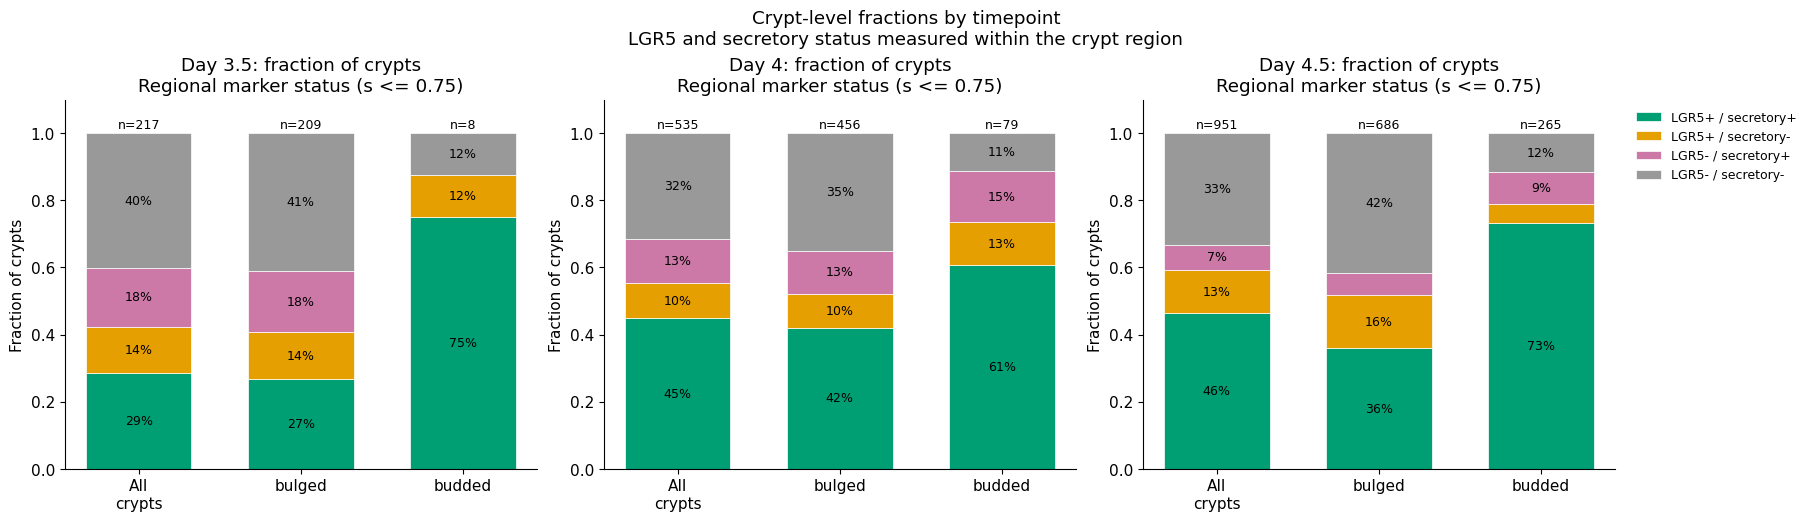

In [6]:
CRYPT_STATUS_ORDER = [
    'LGR5+ / secretory+', 'LGR5+ / secretory-',
    'LGR5- / secretory+', 'LGR5- / secretory-',
]
CRYPT_STATUS_COLORS = dict(zip(CRYPT_STATUS_ORDER, ['#009E73', '#E69F00', '#CC79A7', '#999999']))


def build_crypt_status_fractions(table, timepoints, categories):
    # Input can contain multiple regional records for each crypt.
    crypts = table.loc[table.unit_type == 'crypt'].copy()
    identity = ['timepoint', 'label_ID', 'crypt_id']
    for column in ['crypt_category', 'crypt_has_lgr5', 'crypt_has_secretory']:
        if crypts.groupby(identity)[column].nunique(dropna=False).gt(1).any():
            raise ValueError(f'Inconsistent crypt metadata: {column}')
    crypts = crypts.drop_duplicates(identity)
    if crypts[['crypt_has_lgr5', 'crypt_has_secretory']].isna().any().any():
        raise ValueError('Crypt marker status must be known.')
    lgr5 = crypts.crypt_has_lgr5.astype(bool)
    secretory = crypts.crypt_has_secretory.astype(bool)
    crypts['joint_status'] = np.select(
        [lgr5 & secretory, lgr5 & ~secretory, ~lgr5 & secretory],
        CRYPT_STATUS_ORDER[:3], default=CRYPT_STATUS_ORDER[3])
    category_order = ['All crypts'] + list(categories)
    if (crypts.crypt_category == 'unknown').any():
        category_order += ['unknown']
    rows = []
    for tp in timepoints:
        tp_crypts = crypts.loc[crypts.timepoint == tp]
        for category in category_order:
            selected = tp_crypts if category == 'All crypts' else tp_crypts.loc[tp_crypts.crypt_category == category]
            for status in CRYPT_STATUS_ORDER:
                count = int((selected.joint_status == status).sum())
                rows.append(dict(timepoint=tp, crypt_category=category, joint_status=status,
                                 n_crypts=count, total_crypts=len(selected),
                                 n_organoids=selected.label_ID.nunique(),
                                 fraction=count / len(selected) if len(selected) else np.nan))
    return pd.DataFrame(rows), category_order


crypt_status_fraction_table, crypt_status_categories = build_crypt_status_fractions(
    regional_table, CRYPT_COMPARISON_TIMEPOINTS, REGION_CATEGORIES)
fig_crypt_status, axes = plt.subplots(1, len(CRYPT_COMPARISON_TIMEPOINTS),
    figsize=(6 * len(CRYPT_COMPARISON_TIMEPOINTS), 5.1), squeeze=False, constrained_layout=True)
x = np.arange(len(crypt_status_categories))
for ax, tp in zip(axes[0], CRYPT_COMPARISON_TIMEPOINTS):
    selected = crypt_status_fraction_table.loc[crypt_status_fraction_table.timepoint == tp]
    bottom = np.zeros(len(x))
    for status in CRYPT_STATUS_ORDER:
        part = selected.loc[selected.joint_status == status].set_index('crypt_category').reindex(crypt_status_categories)
        values = part.fraction.fillna(0).to_numpy()
        ax.bar(x, values, bottom=bottom, width=0.65, color=CRYPT_STATUS_COLORS[status],
               label=status, edgecolor='white', linewidth=0.5)
        for position, value, base in zip(x, values, bottom):
            if value >= 0.07:
                ax.text(position, base + value / 2, f'{100 * value:.0f}%', ha='center', va='center', fontsize=9)
        bottom += values
    totals = selected.drop_duplicates('crypt_category').set_index('crypt_category').reindex(crypt_status_categories).total_crypts
    for position, total in zip(x, totals):
        ax.text(position, 1.015, f'n={int(total)}', ha='center', fontsize=9)
        if total == 0:
            ax.text(position, 0.45, 'No crypts', ha='center', rotation=90, fontsize=9)
    ax.set_xticks(x, [label.replace(' ', '\n') for label in crypt_status_categories])
    ax.set_ylim(0, 1.1)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_ylabel('Fraction of crypts')
    tp_label = tp.replace('day', 'Day ').replace('p', '.')
    ax.set_title(f'{tp_label}: fraction of crypts\nRegional marker status (s <= {REGION_CRYPT_MAX:g})')
axes[0, -1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)
fig_crypt_status.suptitle('Crypt-level fractions by timepoint\nLGR5 and secretory status measured within the crypt region')
plt.show()


In [7]:
graph_paths = sorted(GRAPH_DIR.rglob("*.gpickle"))
if not graph_paths:
    raise FileNotFoundError(f"No preprocessed graphs found in {GRAPH_DIR}")
blacklist = load_optional_blacklist(BLACKLIST_PATH) if BLACKLIST_PATH else set()
rows, audit_rows, seen = [], [], set()
for index, graph_path in enumerate(graph_paths, start=1):
    source_timepoint = graph_path.parent.name
    if SELECTED_TIMEPOINTS is not None and source_timepoint not in SELECTED_TIMEPOINTS:
        audit_rows.append(dict(graph_path=str(graph_path), stage="selection", reason="unselected timepoint"))
        continue
    try:
        graph = load_cell_graph(graph_path)  # Trusted local pickle files only.
        label = str(graph.graph.get("label_uid", graph_path.stem))
        if label in blacklist:
            audit_rows.append(dict(graph_path=str(graph_path), stage="selection", reason="blacklisted"))
            continue
        key = (source_timepoint, label)
        if graph.number_of_nodes() < MIN_CELLS:
            audit_rows.append(dict(graph_path=str(graph_path), stage='selection',
                                   reason=f'fewer than {MIN_CELLS} cells'))
            continue
        if key in seen:
            raise ValueError(f"Duplicate organoid {key}")
        seen.add(key)
        row = dict(dataset=DATASET, label_ID=label, source_timepoint=source_timepoint,
                   timepoint=TIMEPOINT_ALIASES.get(source_timepoint, source_timepoint),
                   graph_path=str(graph_path), **summarize_processed_markers(graph))
    except Exception as exc:
        audit_rows.append(dict(graph_path=str(graph_path), stage="graph", reason=str(exc)))
        continue
    row.update(mesh_path=str(graph.graph.get("mesh_path", "")), geometry_valid=False,
               geometry_error="", surface_area_um2=np.nan, volume_um3=np.nan, sphericity=np.nan)
    try:
        mesh_path = resolve_mesh_path(graph, DATASET_ROOT)
        row["mesh_path"] = str(mesh_path)
        row.update(measure_mesh_geometry(OrganoidMesh(str(mesh_path)), MESH_COORD_TO_UM))
        row["geometry_valid"] = True
    except Exception as exc:
        row["geometry_error"] = str(exc)
        audit_rows.append(dict(graph_path=str(graph_path), stage="geometry", reason=str(exc)))
    rows.append(row)
    if index % 250 == 0:
        print(f"Processed {index}/{len(graph_paths)} graph files")
if not rows:
    raise ValueError("No valid graphs remain. Inspect paths, markers, selections and blacklist.")
organoid_table = pd.DataFrame(rows)
audit_table = pd.DataFrame(audit_rows, columns=["graph_path", "stage", "reason"])
geometry_table = organoid_table.loc[organoid_table.geometry_valid].copy()
timepoints = sorted(organoid_table.timepoint.unique(), key=timepoint_sort_key)
timepoint_colors = dict(zip(timepoints, plt.get_cmap("tab10").colors * (1 + len(timepoints) // 10)))
print(f"Retained {len(organoid_table)} organoids; {len(geometry_table)} have valid geometry.")
display(organoid_table.groupby(["timepoint", "source_timepoint"]).agg(
    n_organoids=("label_ID", "size"), n_valid_geometry=("geometry_valid", "sum")))
if len(audit_table):
    display(audit_table.groupby(["stage", "reason"]).size().rename("n_files").to_frame())


Processed 750/2796 graph files


Processed 1250/2796 graph files


Processed 1500/2796 graph files


Processed 1750/2796 graph files


Processed 2000/2796 graph files


Retained 1489 organoids; 1487 have valid geometry.


,,n_organoids,n_valid_geometry
timepoint,source_timepoint,,
day2,day2,62,62
day2p5,day2p5,320,320
day3,day3,443,443
day3p5,day3p5,306,306
day4,day4,358,356


n_files
stage     reason                                                     
geometry  Mesh is not closed/manifold: an edge has other ...        2
selection fewer than 20 cells                                     680
          unselected timepoint                                    627

In [4]:
organoid_table = add_marker_status_columns(organoid_table)
# Rerun this cell and the plot/export cells after changing the thresholds.
organoid_table['shape_category'] = classify_sphericity(
    organoid_table.sphericity, NEAR_SPHERICAL_MIN, NEAR_SPHERICAL_SPLIT, SPHERICAL_MIN)
organoid_table.loc[~organoid_table.geometry_valid, 'shape_category'] = None
geometry_table = organoid_table.loc[organoid_table.geometry_valid].copy()
display(pd.crosstab(geometry_table.timepoint, geometry_table.shape_category).reindex(
    index=timepoints, columns=SHAPE_CATEGORY_ORDER, fill_value=0))


def format_shape_axis(ax, axis='x'):
    labels = [name.replace('-', '-\n').replace(' (', '\n(') for name in SHAPE_CATEGORY_ORDER]
    ticks = range(len(SHAPE_CATEGORY_ORDER))
    if axis == 'x':
        ax.set_xticks(ticks, labels)
        ax.set_xlim(-0.5, len(SHAPE_CATEGORY_ORDER) - 0.5)
    else:
        ax.set_yticks(ticks, labels)
        ax.set_ylim(-0.5, len(SHAPE_CATEGORY_ORDER) - 0.5)


def grouped_shape_boxplots(ax, table, value_column, group_column, groups, colors, labels, panel):
    """One box per color group within each shape category; retain empty-group audit rows."""
    from matplotlib.cbook import boxplot_stats
    from matplotlib.patches import Patch

    width = 0.72 / max(len(groups), 1)
    offsets = (np.arange(len(groups)) - (len(groups) - 1) / 2) * width
    rows = []
    for shape_index, shape in enumerate(SHAPE_CATEGORY_ORDER):
        for offset, group in zip(offsets, groups):
            values = table.loc[(table.shape_category == shape) &
                               (table[group_column] == group), value_column].to_numpy(dtype=float)
            values = values[np.isfinite(values)]
            row = dict(panel=panel, shape_category=shape, value_column=value_column,
                       color_column=group_column, color_group=group, n_organoids=len(values),
                       median=np.nan, q1=np.nan, q3=np.nan, whisker_low=np.nan,
                       whisker_high=np.nan, n_fliers=0)
            if len(values):
                stats = boxplot_stats(values, whis=1.5)[0]
                ax.bxp([stats], positions=[shape_index + offset], widths=width * 0.85,
                       manage_ticks=False, patch_artist=True, showfliers=True,
                       boxprops=dict(facecolor=colors[group], edgecolor=colors[group], alpha=0.75),
                       medianprops=dict(color='black', linewidth=1.2),
                       whiskerprops=dict(color=colors[group]),
                       capprops=dict(color=colors[group]),
                       flierprops=dict(marker='o', markersize=3, markerfacecolor=colors[group],
                                       markeredgecolor='none', alpha=0.5))
                row.update(median=stats['med'], q1=stats['q1'], q3=stats['q3'],
                           whisker_low=stats['whislo'], whisker_high=stats['whishi'],
                           n_fliers=len(stats['fliers']))
            rows.append(row)
    format_shape_axis(ax)
    ax.set_xlabel('Sphericity category')
    ax.grid(axis='y', alpha=0.15)
    ax.set_axisbelow(True)
    handles = [Patch(facecolor=colors[group], label=labels[group], alpha=0.75) for group in groups]
    return rows, handles


shape_category,Non-spherical,Near-spherical (lower),Near-spherical (upper),Spherical
timepoint,,,,
day2,0,0,43,19
day2p5,8,16,181,115
day3,29,27,255,132
day3p5,44,79,120,63
day4,120,74,133,29


## Organoid distributions
The main analysis includes timepoints through **day4** and excludes organoids with fewer than `MIN_CELLS` (default 20) graph nodes.
Sphericity categories are non-spherical (< 0.94), near-spherical lower (0.94 to < 0.965), near-spherical upper (0.965 to < 0.99), and spherical (>= 0.99).
All three thresholds are editable in the configuration cell.
Only geometry-valid organoids enter these figures; raw counts, fractions, sphericity and status are exported per organoid.

Timepoint-colored boxplots show counts and fractions of proliferating and TA cells.
Boxes span the interquartile range, with a median line, whiskers up to 1.5 interquartile ranges, and outlier points.
The secretory-status figure compares fractions using split violins: left = all other organoids, right = organoids with at least one Lysozyme-positive OR Serotonin-positive cell.
Both statuses include all selected timepoints; zero fractions are retained.

All split violins show a solid median and dashed 25th/75th percentiles.
Each half has equal maximum width, independent of sample size, with density restricted to observed extrema.
Single-observation or constant groups are represented by a horizontal line, and empty groups have no glyph.
Sample sizes and distribution statistics are exported alongside the underlying observations.


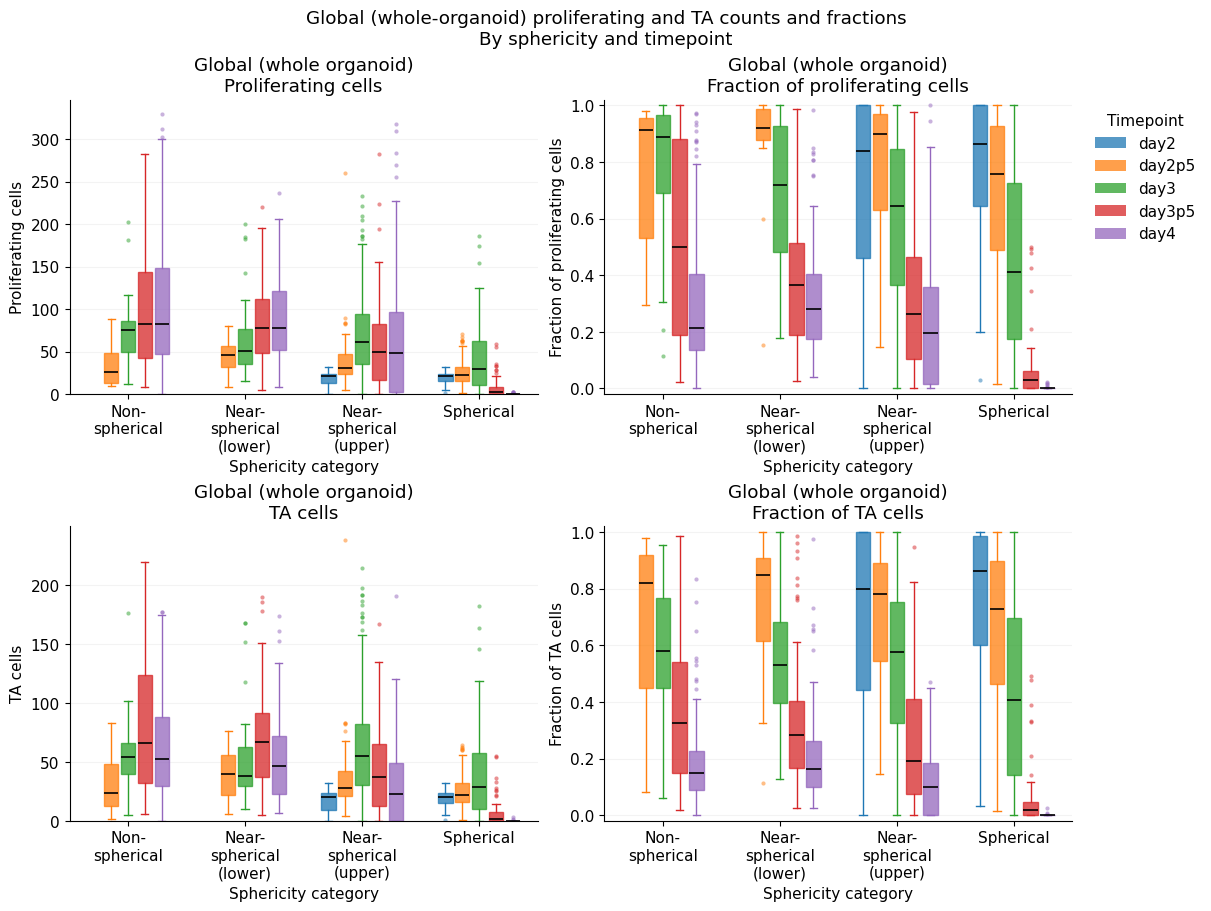

In [5]:
CELL_POPULATIONS = [
    ('proliferating', 'Proliferating cells', 'Fraction of proliferating cells'),
    ('ta', 'TA cells', 'Fraction of TA cells'),
]
boxplot_rows = []
fig_timepoint_boxplots, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for row, (population, count_label, fraction_label) in enumerate(CELL_POPULATIONS):
    for col, (metric, ylabel) in enumerate([
        ('n_' + population, count_label), ('fraction_' + population, fraction_label),
    ]):
        ax = axes[row, col]
        rows, handles = grouped_shape_boxplots(
            ax, geometry_table, metric, 'timepoint', timepoints,
            timepoint_colors, dict(zip(timepoints, timepoints)), panel='timepoint_' + metric)
        boxplot_rows.extend(rows)
        ax.set_ylabel(ylabel)
        ax.set_title(f'Global (whole organoid)\n{ylabel}')
        if col == 0:
            ax.set_ylim(bottom=0)
    axes[row, 1].set_ylim(-0.02, 1.02)
axes[0, 1].legend(handles=handles, title='Timepoint', loc='upper left',
                  bbox_to_anchor=(1.02, 1), frameon=False)
fig_timepoint_boxplots.suptitle('Global (whole-organoid) proliferating and TA counts and fractions\nBy sphericity and timepoint')
boxplot_table = pd.DataFrame(boxplot_rows)
plt.show()


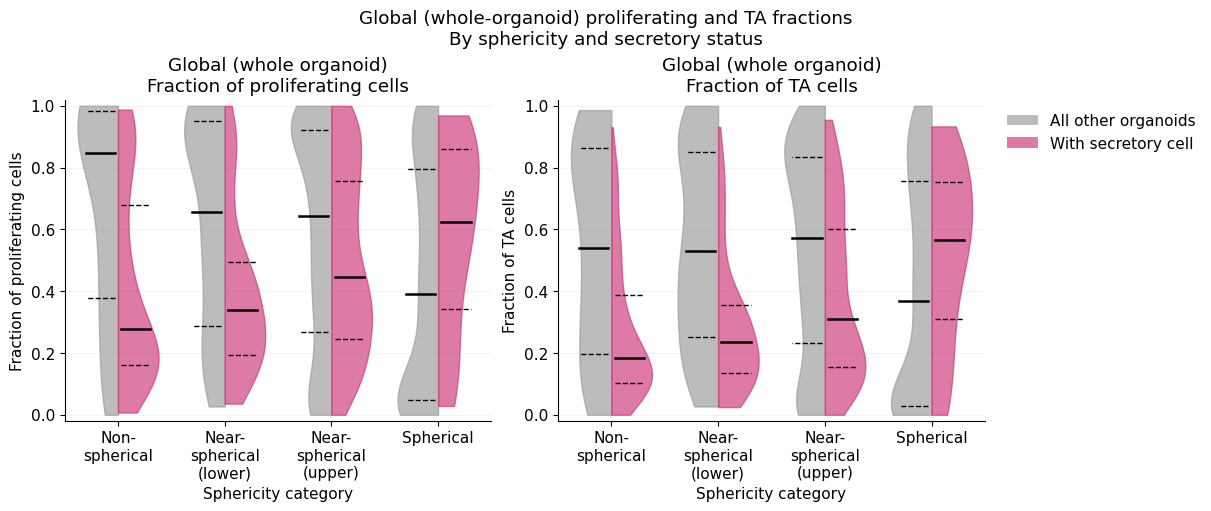

In [6]:
from matplotlib.patches import Patch

SECRETORY_COLORS = {False: '#999999', True: '#CC3377'}
SECRETORY_LABELS = {False: 'All other organoids', True: 'With secretory cell'}
secretory_violin_rows = []
fig_secretory_violins, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, (population, _, fraction_label) in zip(axes, CELL_POPULATIONS):
    metric = 'fraction_' + population
    for position, shape in enumerate(SHAPE_CATEGORY_ORDER):
        for present, side in [(False, 'left'), (True, 'right')]:
            group = geometry_table.loc[
                (geometry_table.shape_category == shape) &
                (geometry_table.has_lysozyme_or_serotonin == present)]
            stats = draw_half_violin(ax, group[metric], position, side, SECRETORY_COLORS[present])
            secretory_violin_rows.append(dict(
                shape_category=shape, metric=metric, has_secretory_cell=present,
                group=SECRETORY_LABELS[present], side=side, n_organoids=len(group), **stats))
    format_shape_axis(ax)
    ax.set_xlabel('Sphericity category')
    ax.set_ylabel(fraction_label)
    ax.set_title(f'Global (whole organoid)\n{fraction_label}')
    ax.set_ylim(-0.02, 1.02)
    ax.grid(axis='y', alpha=0.15)
    ax.set_axisbelow(True)
handles = [Patch(facecolor=SECRETORY_COLORS[p], alpha=0.65, label=SECRETORY_LABELS[p])
           for p in [False, True]]
axes[-1].legend(handles=handles, loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
fig_secretory_violins.suptitle('Global (whole-organoid) proliferating and TA fractions\nBy sphericity and secretory status')
secretory_violin_table = pd.DataFrame(secretory_violin_rows)
plt.show()


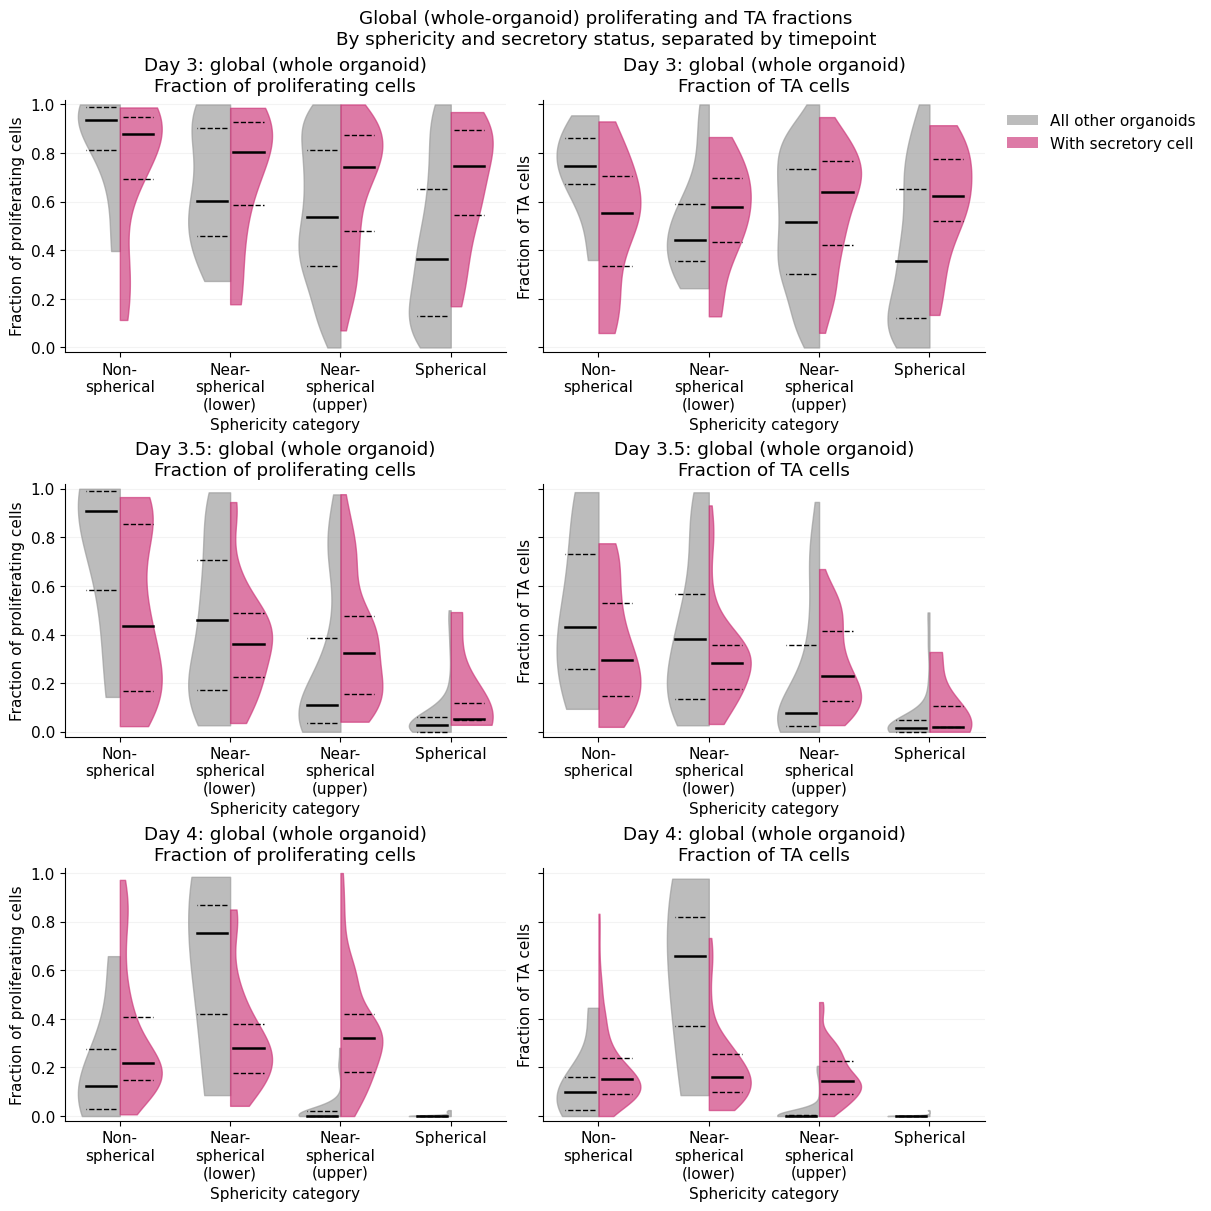

In [7]:
def plot_secretory_fractions_by_timepoint(table, selected_timepoints):
    from matplotlib.patches import Patch

    fig, axes = plt.subplots(len(selected_timepoints), 2,
                             figsize=(12, 4 * len(selected_timepoints)),
                             squeeze=False, sharey=True, constrained_layout=True)
    rows = []
    for row, tp in enumerate(selected_timepoints):
        selected = table.loc[table.timepoint == tp]
        tp_label = tp.replace('day', 'Day ').replace('p', '.')
        for ax, (population, _, fraction_label) in zip(axes[row], CELL_POPULATIONS):
            metric = 'fraction_' + population
            for position, shape in enumerate(SHAPE_CATEGORY_ORDER):
                for present, side in [(False, 'left'), (True, 'right')]:
                    group = selected.loc[
                        (selected.shape_category == shape) &
                        (selected.has_lysozyme_or_serotonin == present)]
                    stats = draw_half_violin(ax, group[metric], position, side, SECRETORY_COLORS[present])
                    rows.append(dict(timepoint=tp, shape_category=shape, metric=metric,
                                     has_secretory_cell=present, group=SECRETORY_LABELS[present],
                                     side=side, n_organoids=len(group), **stats))
            format_shape_axis(ax)
            ax.set_xlabel('Sphericity category')
            ax.set_ylabel(fraction_label)
            ax.set_title(f'{tp_label}: global (whole organoid)\n{fraction_label}')
            ax.set_ylim(-0.02, 1.02)
            ax.grid(axis='y', alpha=0.15)
            ax.set_axisbelow(True)
            if selected.empty:
                ax.text(0.5, 0.5, 'No observations', transform=ax.transAxes, ha='center')
    handles = [Patch(facecolor=SECRETORY_COLORS[p], alpha=0.65, label=SECRETORY_LABELS[p])
               for p in [False, True]]
    axes[0, -1].legend(handles=handles, loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
    fig.suptitle('Global (whole-organoid) proliferating and TA fractions\nBy sphericity and secretory status, separated by timepoint')
    return fig, pd.DataFrame(rows)


fig_secretory_timepoints, secretory_timepoint_table = plot_secretory_fractions_by_timepoint(
    geometry_table, SECRETORY_FIGURE_TIMEPOINTS)
plt.show()


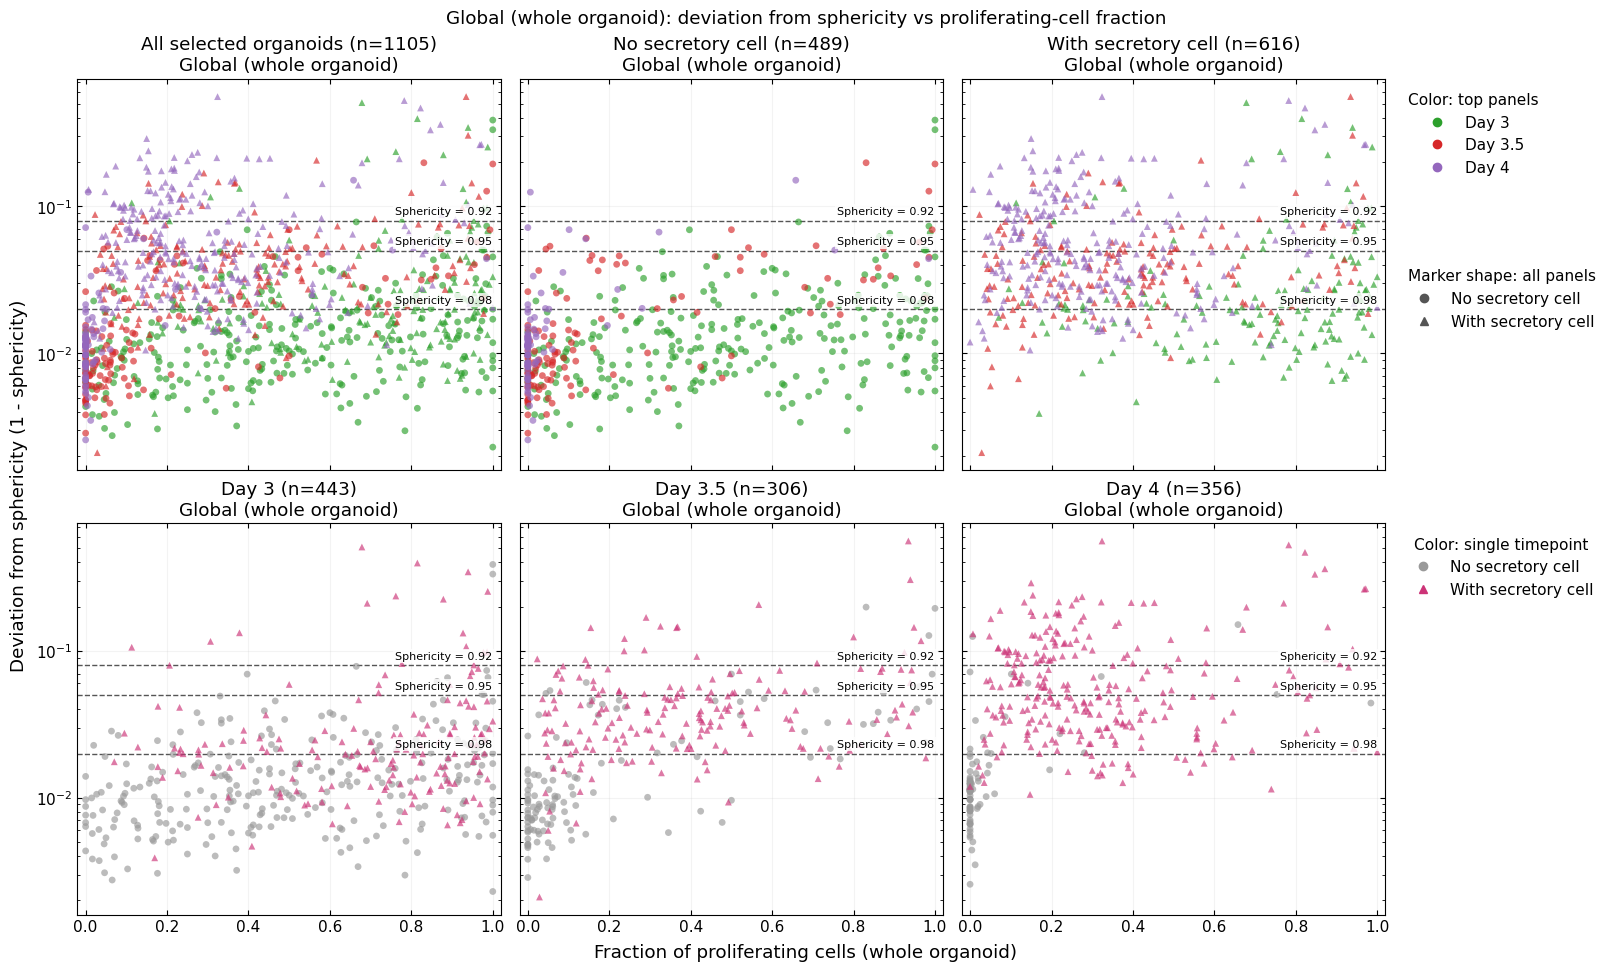

In [4]:
def plot_sphericity_deviation_scatter(table, selected_timepoints, colors, status_colors):
    from matplotlib.lines import Line2D
    from matplotlib.colors import to_hex

    selected = table.loc[
        table.timepoint.isin(selected_timepoints) & table.geometry_valid &
        np.isfinite(table.sphericity) & np.isfinite(table.fraction_proliferating)
    ].copy()
    selected['sphericity_deviation'] = 1.0 - selected.sphericity
    selected['included_in_log_scatter'] = selected.sphericity_deviation > 0
    markers = {False: 'o', True: '^'}
    labels = {False: 'No secretory cell', True: 'With secretory cell'}
    selected['scatter_marker'] = selected.has_lysozyme_or_serotonin.map(markers)
    selected['scatter_color'] = selected.timepoint.map({tp: to_hex(colors[tp]) for tp in selected_timepoints})
    selected['single_timepoint_color'] = selected.has_lysozyme_or_serotonin.map(
        {present: to_hex(color) for present, color in status_colors.items()})
    plotted = selected.loc[selected.included_in_log_scatter]
    panels = [('All selected organoids', plotted, 'timepoint')]
    panels += [(labels[present], plotted.loc[plotted.has_lysozyme_or_serotonin == present], 'timepoint')
               for present in [False, True]]
    panels += [(tp.replace('day', 'Day ').replace('p', '.'), plotted.loc[plotted.timepoint == tp], 'secretory')
               for tp in selected_timepoints]
    nrows = (len(panels) + 2) // 3
    fig, axes = plt.subplots(nrows, 3, figsize=(16, 4.8 * nrows), squeeze=False,
                             sharex=True, sharey=True, constrained_layout=True)
    for ax, (title, subset, color_by) in zip(axes.flat, panels):
        for tp in selected_timepoints:
            for present in [False, True]:
                group = subset.loc[
                    (subset.timepoint == tp) & (subset.has_lysozyme_or_serotonin == present)]
                ax.scatter(group.fraction_proliferating, group.sphericity_deviation,
                           color=status_colors[present] if color_by == 'secretory' else colors[tp],
                           marker=markers[present], s=24, alpha=0.65,
                           edgecolors='none')
        ax.set_xlim(-0.02, 1.02)
        ax.set_yscale('log')
        ax.spines['top'].set_visible(True)
        ax.spines['right'].set_visible(True)
        ax.tick_params(axis='both', which='both', top=True, right=True, direction='in')
        for threshold in [SPHERICAL_MIN, NEAR_SPHERICAL_SPLIT, NEAR_SPHERICAL_MIN]:
            deviation = 1.0 - threshold
            ax.axhline(deviation, color='#555555', linestyle='--', linewidth=1, zorder=0.9)
            ax.annotate(f'Sphericity = {threshold:g}', xy=(0.98, deviation),
                        xycoords=ax.get_yaxis_transform(), xytext=(0, 3),
                        textcoords='offset points', ha='right', va='bottom', fontsize=8,
                        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1.5))
        ax.grid(alpha=0.15)
        ax.set_axisbelow(True)
        ax.set_title(f'{title} (n={len(subset)})\nGlobal (whole organoid)')
        if subset.empty:
            ax.text(0.5, 0.5, 'No positive deviations', transform=ax.transAxes, ha='center')
    for ax in list(axes.flat)[len(panels):]:
        fig.delaxes(ax)
    time_handles = [Line2D([], [], color=colors[tp], marker='o', linestyle='none',
                           label=tp.replace('day', 'Day ').replace('p', '.'))
                    for tp in selected_timepoints]
    legend_ax = axes[0, -1]
    time_legend = legend_ax.legend(handles=time_handles, title='Color: top panels', loc='upper left',
                                   bbox_to_anchor=(1.02, 1), frameon=False)
    legend_ax.add_artist(time_legend)
    status_handles = [Line2D([], [], color='#555555', marker=markers[p], linestyle='none',
                             label=labels[p]) for p in [False, True]]
    legend_ax.legend(handles=status_handles, title='Marker shape: all panels',
                     loc='upper left', bbox_to_anchor=(1.02, 0.55), frameon=False)
    single_timepoint_handles = [Line2D([], [], color=status_colors[p], marker=markers[p],
                                      linestyle='none', label=labels[p]) for p in [False, True]]
    if selected_timepoints:
        fig.axes[-1].legend(handles=single_timepoint_handles, title='Color: single timepoint',
                            loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
    fig.supxlabel('Fraction of proliferating cells (whole organoid)')
    fig.supylabel('Deviation from sphericity (1 - sphericity)')
    fig.suptitle('Global (whole organoid): deviation from sphericity vs proliferating-cell fraction')
    return fig, selected


fig_deviation_scatter, deviation_scatter_table = plot_sphericity_deviation_scatter(
    organoid_table, DEVIATION_SCATTER_TIMEPOINTS, timepoint_colors, SECRETORY_COLORS)
plt.show()


## Distribution ellipses (positive proliferation only)
The top two panels contain the same organoids from day3, day3p5 and day4, excluding zero proliferating-cell fractions and nonpositive deviations.
Colors identify timepoint in the top-left panel and secretory status in the top-right; circles/triangles retain the absence/presence of secretory cells.
The bottom panels show organoids without (left) or with (right) secretory cells, with separate timepoint-colored ellipses fitted to each timepoint within that secretory group.
Ellipses use the sample covariance of (proliferating-cell fraction, log10(1 - sphericity)), with semi-axes scaled by `SCATTER_ELLIPSE_N_STD` (default 1).
These describe spread, not confidence in the mean or a guaranteed fraction of observations.
The unbounded elliptical approximation can extend outside the physically possible fraction range; the data themselves are unchanged and the full contours are shown.
Groups with fewer than three observations or degenerate covariance have no ellipse; their points remain visible and the reason is exported.


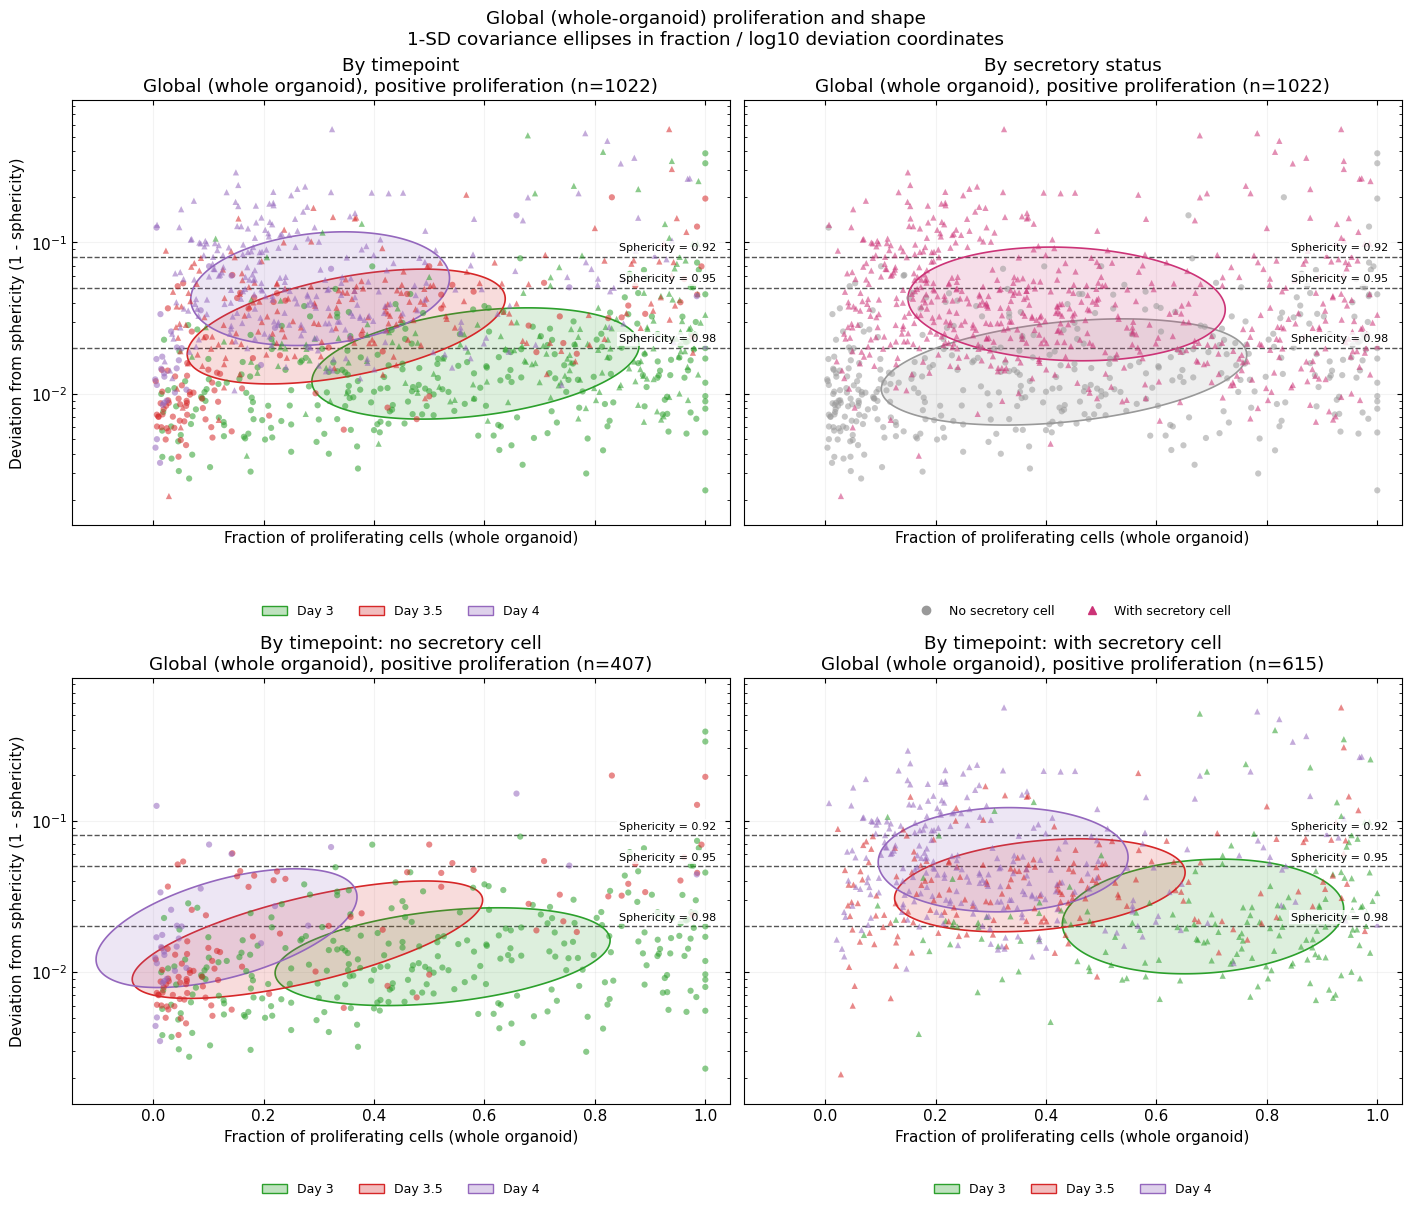

In [3]:
def covariance_ellipse_coordinates(fractions, deviations, n_std):
    """Summarize spread in linear x / log10 y; do not interpret as a mean confidence interval."""
    if not np.isfinite(n_std) or n_std <= 0:
        raise ValueError('Ellipse radius must be finite and positive.')
    x, y = np.asarray(fractions, dtype=float), np.asarray(deviations, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y) & (y > 0)
    points = np.column_stack([x[valid], np.log10(y[valid])])
    stats = dict(n_organoids=len(points), n_std=n_std, mean_fraction=np.nan,
                 mean_log10_deviation=np.nan, cov_xx=np.nan, cov_xy=np.nan, cov_yy=np.nan,
                 ellipse_status='fewer than three observations')
    if len(points):
        stats.update(mean_fraction=float(points[:, 0].mean()),
                     mean_log10_deviation=float(points[:, 1].mean()))
    if len(points) < 3:
        return None, stats
    covariance = np.cov(points, rowvar=False, ddof=1)
    stats.update(cov_xx=float(covariance[0, 0]), cov_xy=float(covariance[0, 1]),
                 cov_yy=float(covariance[1, 1]))
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    if eigenvalues[0] <= np.finfo(float).eps * max(float(eigenvalues[-1]), 1.0):
        stats['ellipse_status'] = 'degenerate covariance'
        return None, stats
    angle = np.linspace(0, 2 * np.pi, 361)
    circle = np.vstack([np.cos(angle), np.sin(angle)])
    contour = points.mean(axis=0)[:, None] + eigenvectors @ (n_std * np.sqrt(eigenvalues)[:, None] * circle)
    stats['ellipse_status'] = 'drawn'
    return np.column_stack([contour[0], 10.0 ** contour[1]]), stats


def plot_deviation_distribution_ellipses(scatter_table, selected_timepoints, colors, status_colors, n_std):
    from matplotlib.colors import to_hex, to_rgba
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch

    positive = scatter_table.loc[
        scatter_table.timepoint.isin(selected_timepoints) &
        np.isfinite(scatter_table.fraction_proliferating) &
        (scatter_table.fraction_proliferating > 0) &
        np.isfinite(scatter_table.sphericity_deviation) &
        (scatter_table.sphericity_deviation > 0)
    ].copy()
    markers = {False: 'o', True: '^'}
    labels = {False: 'No secretory cell', True: 'With secretory cell'}
    positive['secretory_panel_color'] = positive.has_lysozyme_or_serotonin.map(
        {key: to_hex(value) for key, value in status_colors.items()})
    fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharex=True, sharey=True, constrained_layout=True)
    panels = [('timepoint', 'By timepoint', None),
              ('secretory_status', 'By secretory status', None),
              ('timepoint_no_secretory', 'By timepoint: no secretory cell', False),
              ('timepoint_with_secretory', 'By timepoint: with secretory cell', True)]
    summaries = []
    for ax, (panel, title, secretory_filter) in zip(axes.flat, panels):
        panel_data = positive if secretory_filter is None else positive.loc[
            positive.has_lysozyme_or_serotonin == secretory_filter]
        if panel != 'secretory_status':
            groups = [(tp, tp.replace('day', 'Day ').replace('p', '.'),
                       panel_data.loc[panel_data.timepoint == tp], colors[tp]) for tp in selected_timepoints]
        else:
            groups = [(present, labels[present],
                       panel_data.loc[panel_data.has_lysozyme_or_serotonin == present], status_colors[present])
                      for present in [False, True]]
        for key, label, group, color in groups:
            contour, stats = covariance_ellipse_coordinates(
                group.fraction_proliferating, group.sphericity_deviation, n_std)
            summaries.append(dict(panel=panel, secretory_filter=secretory_filter,
                                  group=key, label=label, color=to_hex(color), **stats))
            if contour is not None:
                ax.fill(contour[:, 0], contour[:, 1], facecolor=to_rgba(color, 0.16),
                        edgecolor=color, linewidth=1.2, zorder=1)
            for present in [False, True]:
                subset = group.loc[group.has_lysozyme_or_serotonin == present]
                ax.scatter(subset.fraction_proliferating, subset.sphericity_deviation,
                           color=color, marker=markers[present], s=20, alpha=0.55,
                           edgecolors='none', zorder=2)
        ax.set_yscale('log')
        ax.spines['top'].set_visible(True)
        ax.spines['right'].set_visible(True)
        ax.tick_params(axis='both', which='both', top=True, right=True, direction='in')
        for threshold in [SPHERICAL_MIN, NEAR_SPHERICAL_SPLIT, NEAR_SPHERICAL_MIN]:
            deviation = 1.0 - threshold
            ax.axhline(deviation, color='#555555', linestyle='--', linewidth=1, zorder=0.9)
            ax.annotate(f'Sphericity = {threshold:g}', xy=(0.98, deviation),
                        xycoords=ax.get_yaxis_transform(), xytext=(0, 3),
                        textcoords='offset points', ha='right', va='bottom', fontsize=8,
                        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1.5))
        ax.grid(alpha=0.15)
        ax.set_axisbelow(True)
        ax.margins(x=0.04, y=0.08)
        ax.set_title(f'{title}\nGlobal (whole organoid), positive proliferation (n={len(panel_data)})')
        ax.set_xlabel('Fraction of proliferating cells (whole organoid)')
        if panel != 'secretory_status':
            handles = [Patch(facecolor=to_rgba(color, .3), edgecolor=color, label=label)
                       for _, label, _, color in groups]
        else:
            handles = [Line2D([], [], color=color, marker=markers[key], linestyle='none', label=label)
                       for key, label, _, color in groups]
        ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, -0.16),
                  ncol=len(handles), frameon=False, fontsize=9)
        if panel_data.empty:
            ax.text(0.5, 0.5, 'No observations', transform=ax.transAxes, ha='center')
    for ax in axes[:, 0]:
        ax.set_ylabel('Deviation from sphericity (1 - sphericity)')
    fig.suptitle(f'Global (whole-organoid) proliferation and shape\n{n_std:g}-SD covariance ellipses in fraction / log10 deviation coordinates')
    return fig, positive, pd.DataFrame(summaries)


fig_deviation_ellipses, deviation_ellipse_data, deviation_ellipse_statistics = plot_deviation_distribution_ellipses(
    deviation_scatter_table, DEVIATION_SCATTER_TIMEPOINTS, timepoint_colors,
    SECRETORY_COLORS, SCATTER_ELLIPSE_N_STD)
plt.show()


In [9]:
if EXPORT:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    organoid_table.to_csv(EXPORT_DIR / "proliferation_shape_by_organoid.csv", index=False)
    audit_table.to_csv(EXPORT_DIR / "excluded_or_invalid_files.csv", index=False)
    boxplot_table.to_csv(EXPORT_DIR / "grouped_boxplot_statistics.csv", index=False)
    secretory_violin_table.to_csv(EXPORT_DIR / "secretory_split_violin_statistics.csv", index=False)
    secretory_timepoint_table.to_csv(EXPORT_DIR / "secretory_split_violin_statistics_by_timepoint.csv", index=False)
    deviation_scatter_table.to_csv(EXPORT_DIR / "sphericity_deviation_proliferation_scatter_data.csv", index=False)
    deviation_ellipse_data.to_csv(EXPORT_DIR / "sphericity_deviation_ellipse_data.csv", index=False)
    deviation_ellipse_statistics.to_csv(EXPORT_DIR / "sphericity_deviation_ellipse_statistics.csv", index=False)
    settings = dict(
        dataset=DATASET, graph_dir=str(GRAPH_DIR), selected_timepoints=SELECTED_TIMEPOINTS,
        secretory_figure_timepoints=SECRETORY_FIGURE_TIMEPOINTS,
        deviation_scatter_timepoints=DEVIATION_SCATTER_TIMEPOINTS,
        deviation_scatter_panels=['all', 'no_secretory', 'with_secretory', *DEVIATION_SCATTER_TIMEPOINTS],
        deviation_scatter_shared_axes=True,
        deviation_scatter_color_by={'top_panels': 'timepoint', 'single_timepoint_panels': 'secretory_status'},
        deviation_scatter_status_colors={str(p): color for p, color in SECRETORY_COLORS.items()},
        deviation_ellipse_n_std=SCATTER_ELLIPSE_N_STD,
        deviation_ellipse_panels=['timepoint', 'secretory_status', 'timepoint_no_secretory', 'timepoint_with_secretory'],
        deviation_ellipse_coordinates=['fraction_proliferating', 'log10(sphericity_deviation)'],
        deviation_ellipse_filter='fraction_proliferating > 0 and sphericity_deviation > 0',
        deviation_ellipse_covariance_ddof=1,
        deviation_scatter_sphericity_thresholds=[NEAR_SPHERICAL_MIN, NEAR_SPHERICAL_SPLIT, SPHERICAL_MIN],
        deviation_scatter_x='fraction_proliferating', deviation_scatter_y='1 - sphericity',
        deviation_scatter_yscale='log', deviation_scatter_nonpositive='omit; flag in exported plot data',
        deviation_scatter_markers={'no_secretory_cell': 'o', 'with_secretory_cell': '^'},
        min_cells=MIN_CELLS, near_spherical_min=NEAR_SPHERICAL_MIN,
        near_spherical_split=NEAR_SPHERICAL_SPLIT, spherical_min=SPHERICAL_MIN,
        shape_category_order=SHAPE_CATEGORY_ORDER, timepoint_aliases=TIMEPOINT_ALIASES,
        timepoint_colors={k: list(v) for k, v in timepoint_colors.items()},
        blacklist_path=str(BLACKLIST_PATH) if BLACKLIST_PATH else None,
        marker_field="markers_bin", proliferation_markers=["Cyclin A", "Cyclin D"],
        proliferation_rule="any positive (>0), count each cell once",
        ta_rule="Cyclin A or D positive; no other measured marker positive",
        status_rule="at least one Lysozyme-positive OR Serotonin-positive cell in the organoid",
        secretory_violin_sides={"left": SECRETORY_LABELS[False], "right": SECRETORY_LABELS[True]},
        secretory_violin_colors={SECRETORY_LABELS[k]: v for k, v in SECRETORY_COLORS.items()},
        violin_density="Gaussian KDE, Scott bandwidth, 100 points, bounded by sample extrema",
        violin_normalization="equal maximum width for each half; not proportional to sample size",
        violin_summary="solid median, dashed 25th and 75th percentiles",
        violin_constant_group="horizontal line; no KDE", boxplot_whisker_iqr=1.5,
        boxplot_show_fliers=True,
        sphericity_formula="pi^(1/3) * (6*volume)^(2/3) / surface_area",
        mesh_coord_to_um=MESH_COORD_TO_UM, geometry_source="original linked mesh",
        geometry_smoothing=False, n_organoids=len(organoid_table),
        n_valid_geometry=len(geometry_table))
    (EXPORT_DIR / "analysis_settings.json").write_text(json.dumps(settings, indent=2) + "\n")
    for name, fig in [("proliferation_by_timepoint_boxplots", fig_timepoint_boxplots),
                      ("proliferation_secretory_split_violins", fig_secretory_violins),
                      ("proliferation_secretory_split_violins_by_timepoint", fig_secretory_timepoints),
                      ("sphericity_deviation_proliferation_scatter", fig_deviation_scatter),
                      ("sphericity_deviation_distribution_ellipses", fig_deviation_ellipses)]:
        fig.savefig(EXPORT_DIR / f"{name}.svg", bbox_inches="tight")
        fig.savefig(EXPORT_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    print(f"Exported figures and per-organoid plot data to {EXPORT_DIR}")


Exported figures and per-organoid plot data to /home/fmoller/Projects/LearningOrganoids/OrganoGraph/exports/proliferation_symmetry_breaking/20250929


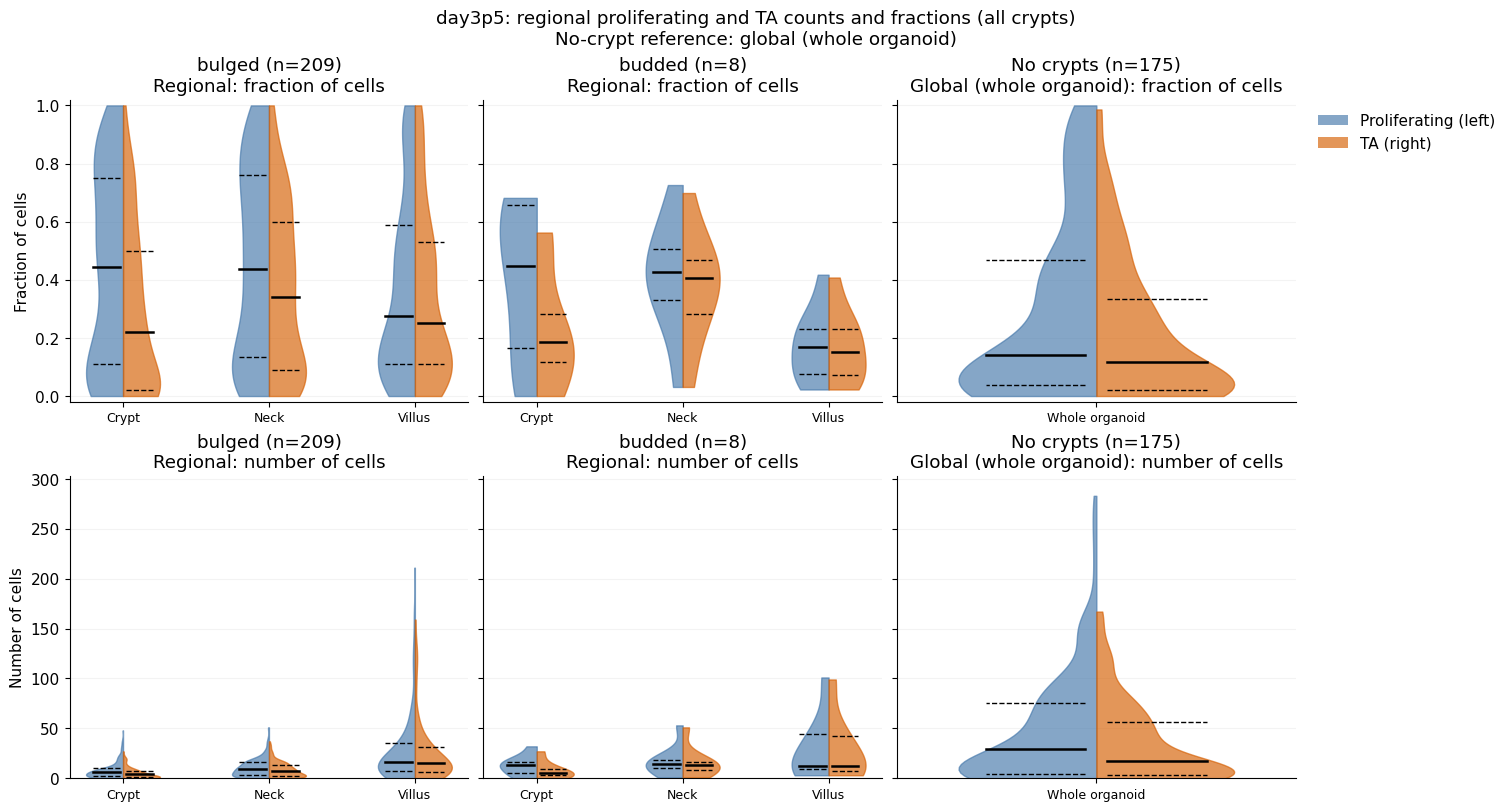

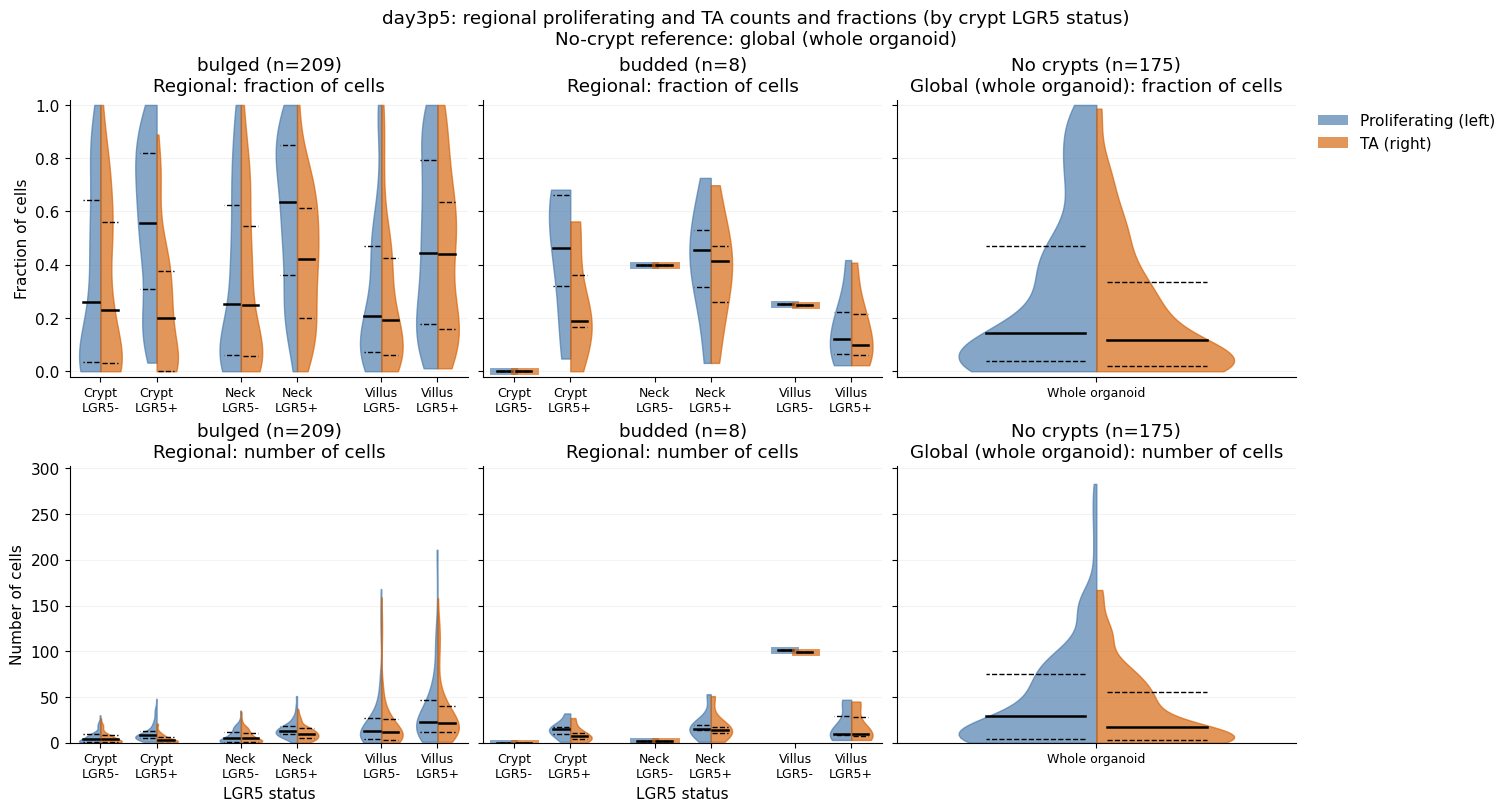

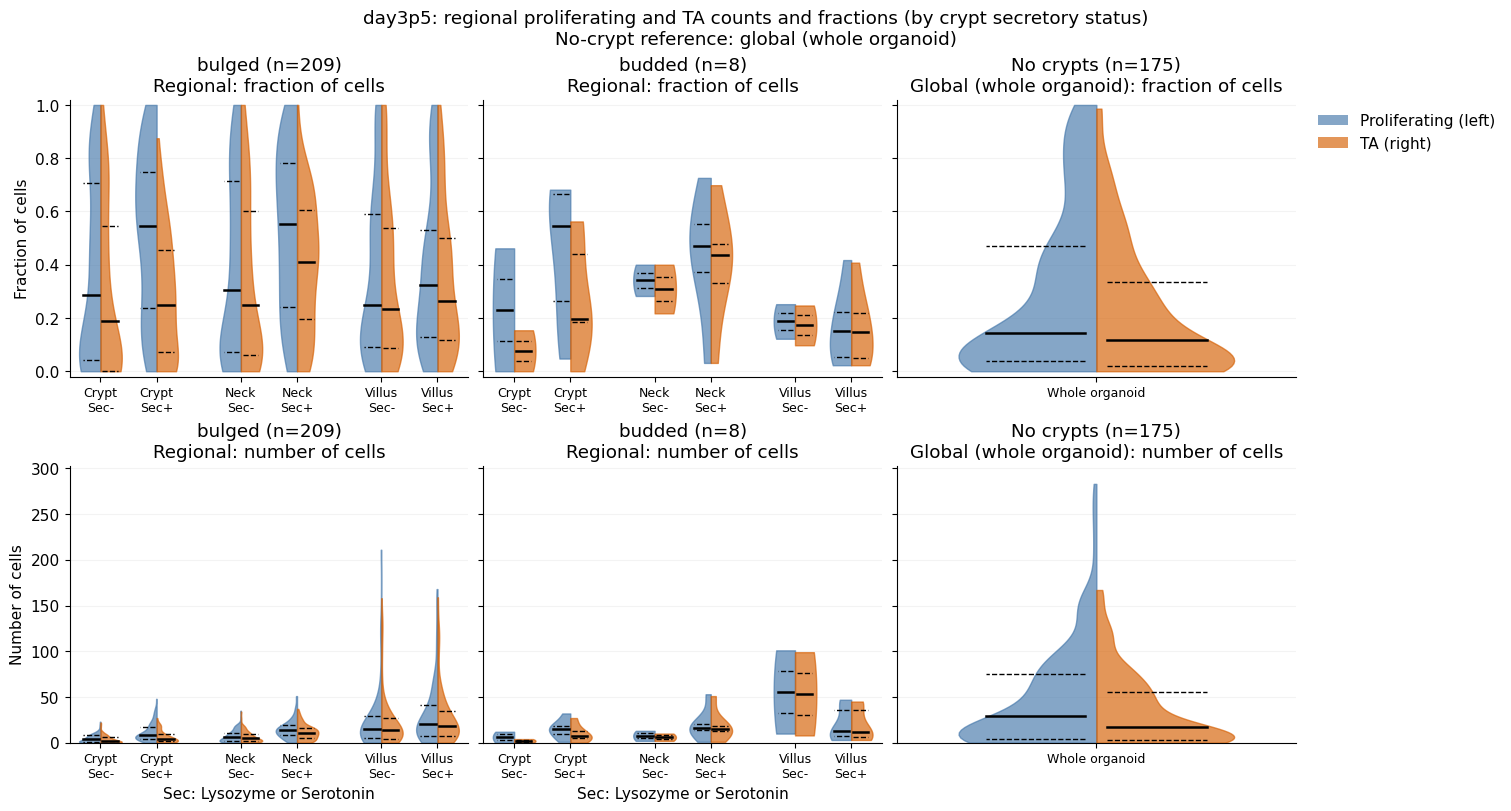

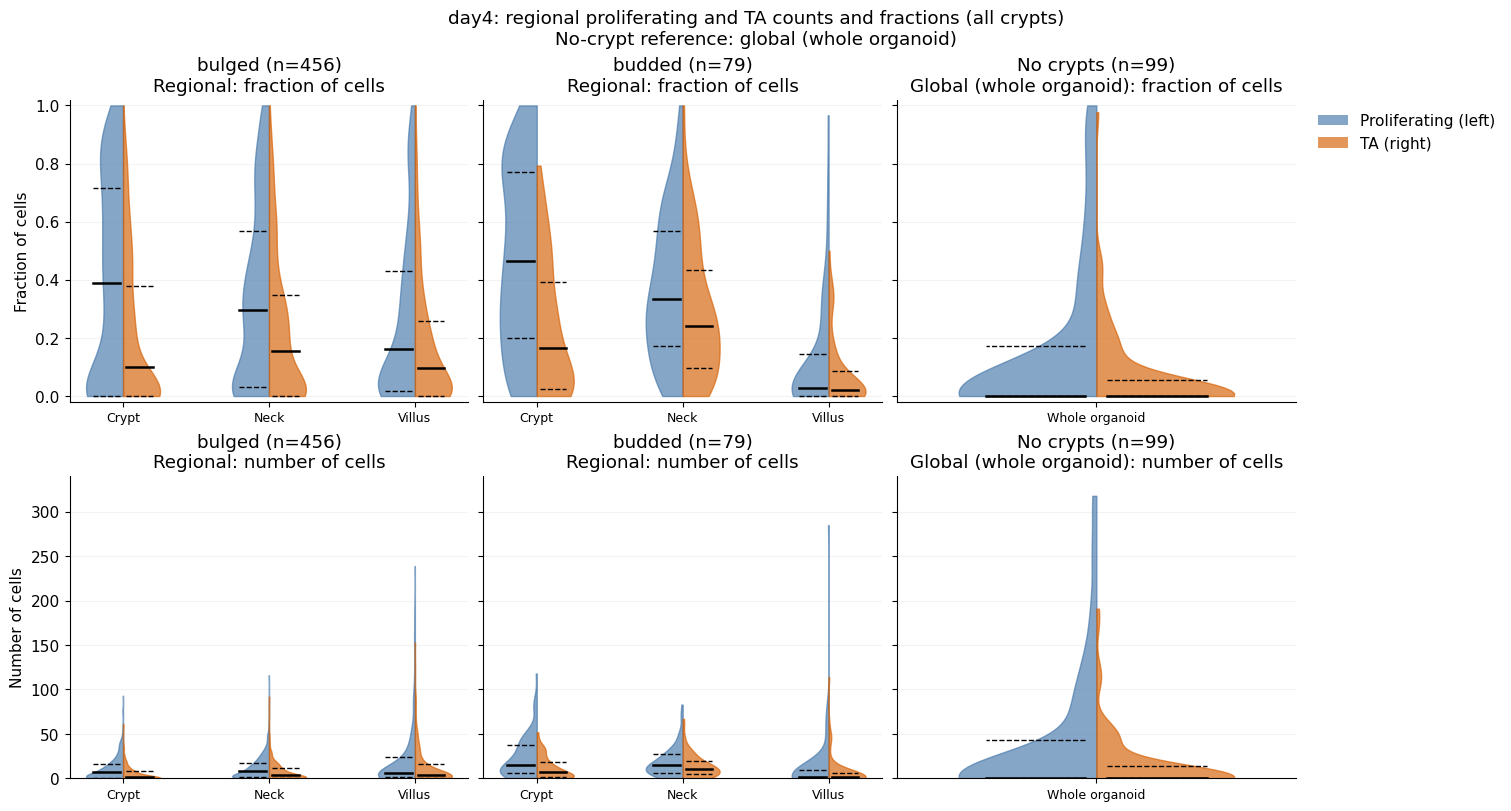

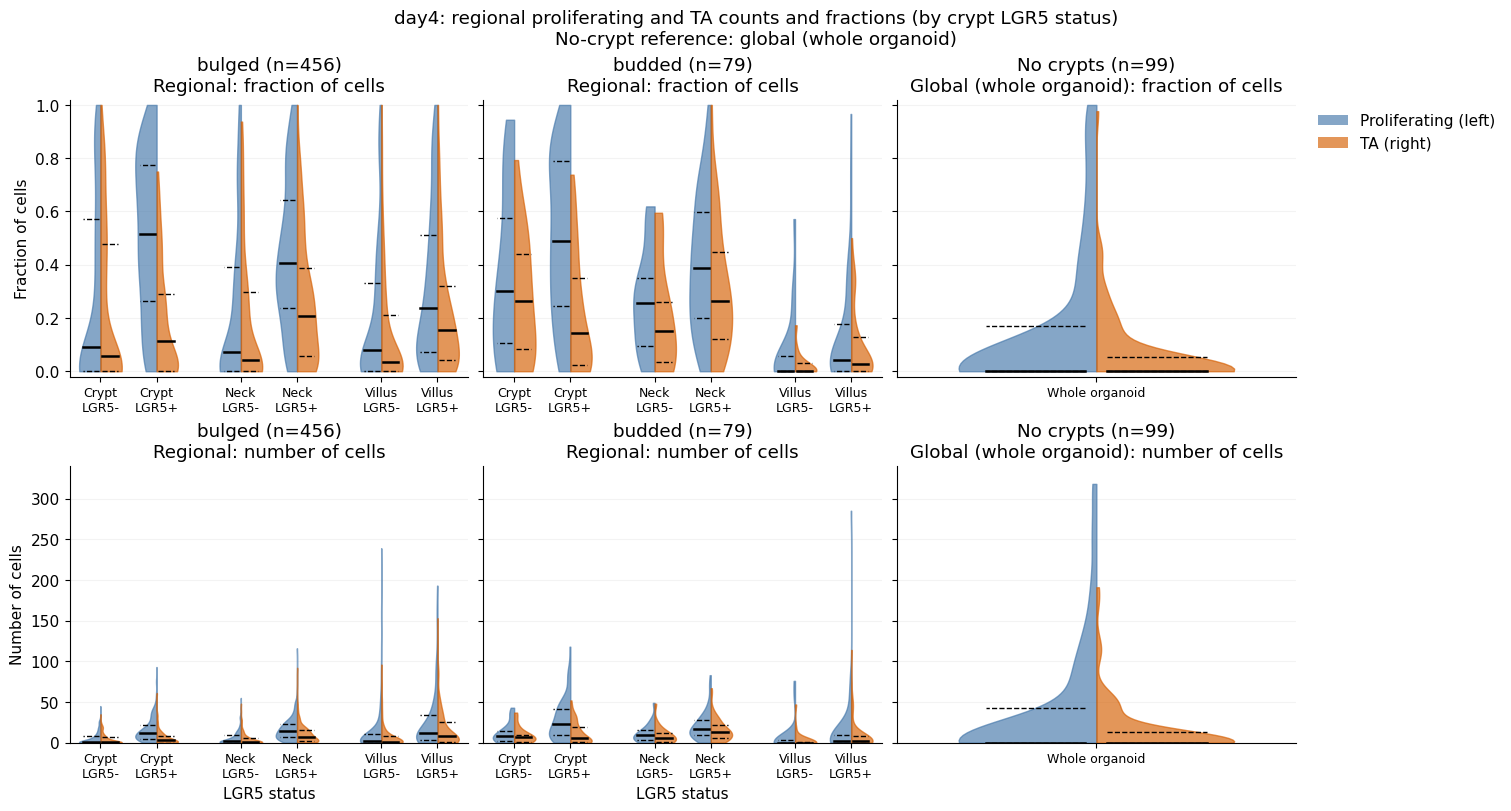

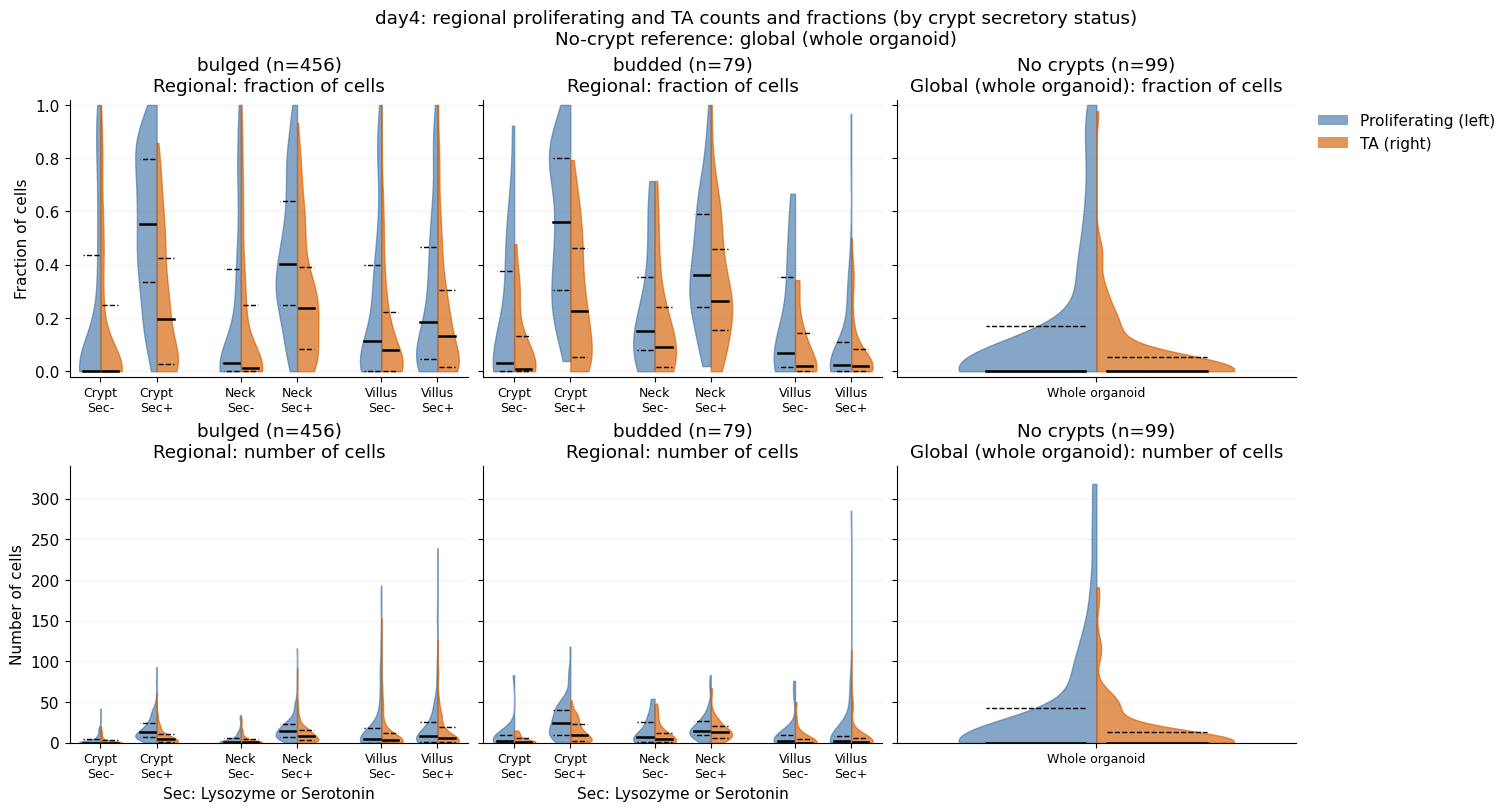

In [7]:
def plot_regional_proliferation(table, tp, split_field=None):
    from matplotlib.patches import Patch

    categories = list(REGION_CATEGORIES)
    if (table.crypt_category == 'unknown').any():
        categories.append('unknown')
    categories += ['No crypts']
    colors = {'proliferating': '#4477AA', 'ta': '#D55E00'}
    fig, axes = plt.subplots(2, len(categories), figsize=(5 * len(categories), 8),
                              squeeze=False, sharey='row', constrained_layout=True)
    summaries = []
    for col, category in enumerate(categories):
        subset = table.loc[(table.timepoint == tp) & (table.crypt_category == category)]
        regions = ['Whole organoid'] if category == 'No crypts' else ['Crypt', 'Neck', 'Villus']
        if category == 'No crypts':
            groups = [(None, 'No crypts (unsplit)', '')]
        elif split_field:
            marker = 'LGR5' if split_field == 'crypt_has_lgr5' else 'Secretory'
            short_marker = 'LGR5' if split_field == 'crypt_has_lgr5' else 'Sec'
            groups = [(False, f'No {marker}+ crypt cells', short_marker + '-'),
                      (True, f'At least one {marker}+ crypt cell', short_marker + '+')]
        else:
            groups = [(None, 'All crypts', '')]
        ticks, ticklabels = [], []
        for r, region in enumerate(regions):
            for g, (value, label, short_label) in enumerate(groups):
                position = r * (len(groups) + 0.5) + g
                ticks.append(position)
                ticklabels.append(region + ('\n' + short_label if short_label else ''))
                group = subset.loc[subset.region == region]
                if value is not None:
                    group = group.loc[group[split_field] == value]
                for row, prefix in enumerate(['fraction_', 'n_']):
                    for population, side in [('proliferating', 'left'), ('ta', 'right')]:
                        metric = prefix + population
                        stats = draw_half_violin(
                            axes[row, col], group[metric], position, side, colors[population])
                        summaries.append(dict(
                            timepoint=tp, split=split_field or 'all', crypt_category=category,
                            region=region, group=label, metric=metric, population=population,
                            side=side, n_units=len(group), n_organoids=group.label_ID.nunique(),
                            total_cells=int(group.n_cells.sum()),
                            total_proliferating=int(group.n_proliferating.sum()),
                            total_ta=int(group.n_ta.sum()), **stats))
        for row, ylabel in enumerate(['Fraction of cells', 'Number of cells']):
            ax = axes[row, col]
            ax.set_xticks(ticks, ticklabels, fontsize=9)
            ax.set_xlim(min(ticks) - 0.55, max(ticks) + 0.55)
            ax.set_ylabel(ylabel if col == 0 else '')
            if row == 1 and split_field and category != 'No crypts':
                ax.set_xlabel('LGR5 status' if split_field == 'crypt_has_lgr5'
                              else 'Sec: Lysozyme or Serotonin')
            ax.grid(axis='y', alpha=0.15)
            ax.set_axisbelow(True)
            if row == 0:
                ax.set_ylim(-0.02, 1.02)
            n_units = subset[['label_ID', 'crypt_id']].drop_duplicates().shape[0]
            scope = 'Global (whole organoid)' if category == 'No crypts' else 'Regional'
            ax.set_title(f'{category} (n={n_units})\n{scope}: {ylabel.lower()}')
            if subset.empty:
                ax.text(0.5, 0.5, 'No observations', transform=ax.transAxes, ha='center')
    count_values = table.loc[table.timepoint == tp, ['n_proliferating', 'n_ta']].to_numpy(dtype=float)
    count_values = count_values[np.isfinite(count_values)]
    count_max = float(count_values.max()) if len(count_values) else 0.0
    axes[1, 0].set_ylim(0, max(1.0, count_max * 1.07))
    handles = [Patch(facecolor=colors[p], label=label, alpha=0.65)
               for p, label in [('proliferating', 'Proliferating (left)'), ('ta', 'TA (right)')]]
    axes[0, -1].legend(handles=handles, loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
    title = {'crypt_has_lgr5': 'by crypt LGR5 status',
             'crypt_has_secretory': 'by crypt secretory status', None: 'all crypts'}[split_field]
    fig.suptitle(f'{tp}: regional proliferating and TA counts and fractions ({title})\nNo-crypt reference: global (whole organoid)')
    return fig, pd.DataFrame(summaries)


regional_figures = {}
regional_summaries = []
for tp in REGION_TIMEPOINTS:
    for suffix, split in [('all', None), ('lgr5', 'crypt_has_lgr5'), ('secretory', 'crypt_has_secretory')]:
        fig, summary = plot_regional_proliferation(regional_table, tp, split)
        regional_figures[f'regional_proliferation_{tp}_{suffix}'] = fig
        regional_summaries.append(summary)
        plt.show()
regional_plot_summary = pd.concat(regional_summaries, ignore_index=True)


## Regional proliferation: crypt vs villus
Each point pairs one crypt's proliferating-cell fraction (y-axis) with the fraction in its own assigned villus territory (x-axis).
Timepoints day3p5, day4 and day4p5 are overlaid by color; day4p5 pools source folders day4p5 and day4p5-more.
Rows distinguish bulged and budded crypts; columns show the four combinations of crypt LGR5 and secretory status.
Status is determined from assigned Crypt cells only (s <= 0.75); secretory means Lysozyme OR Serotonin.
The existing nearest-normalized-distance assignment is retained: Villus cells have s >= 1.15 and belong to only one crypt's territory.
Each fraction uses all cells in its own region as denominator, without pooling organoids or crypts; multiple crypts from the same organoid are not independent biological replicates.
Genuine zero fractions are included, but missing/empty regions, undefined fractions or unclassified crypts are excluded and flagged in the exported paired table.
Organoids without crypts do not contribute to this comparison.
The dashed diagonal indicates equal crypt and villus proliferation fractions.
Shaded ellipses show 1-SD sample covariance in the two linear fractions (not confidence intervals); zeros are included. Groups with fewer than three pairs or degenerate covariance have points but no ellipse. Ellipses extending beyond the panel limits are clipped.


Plotted 1661 paired crypts; excluded 42.


,,n_crypts
timepoint,exclusion_reason,
day4,empty region,17
day4p5,empty region,25


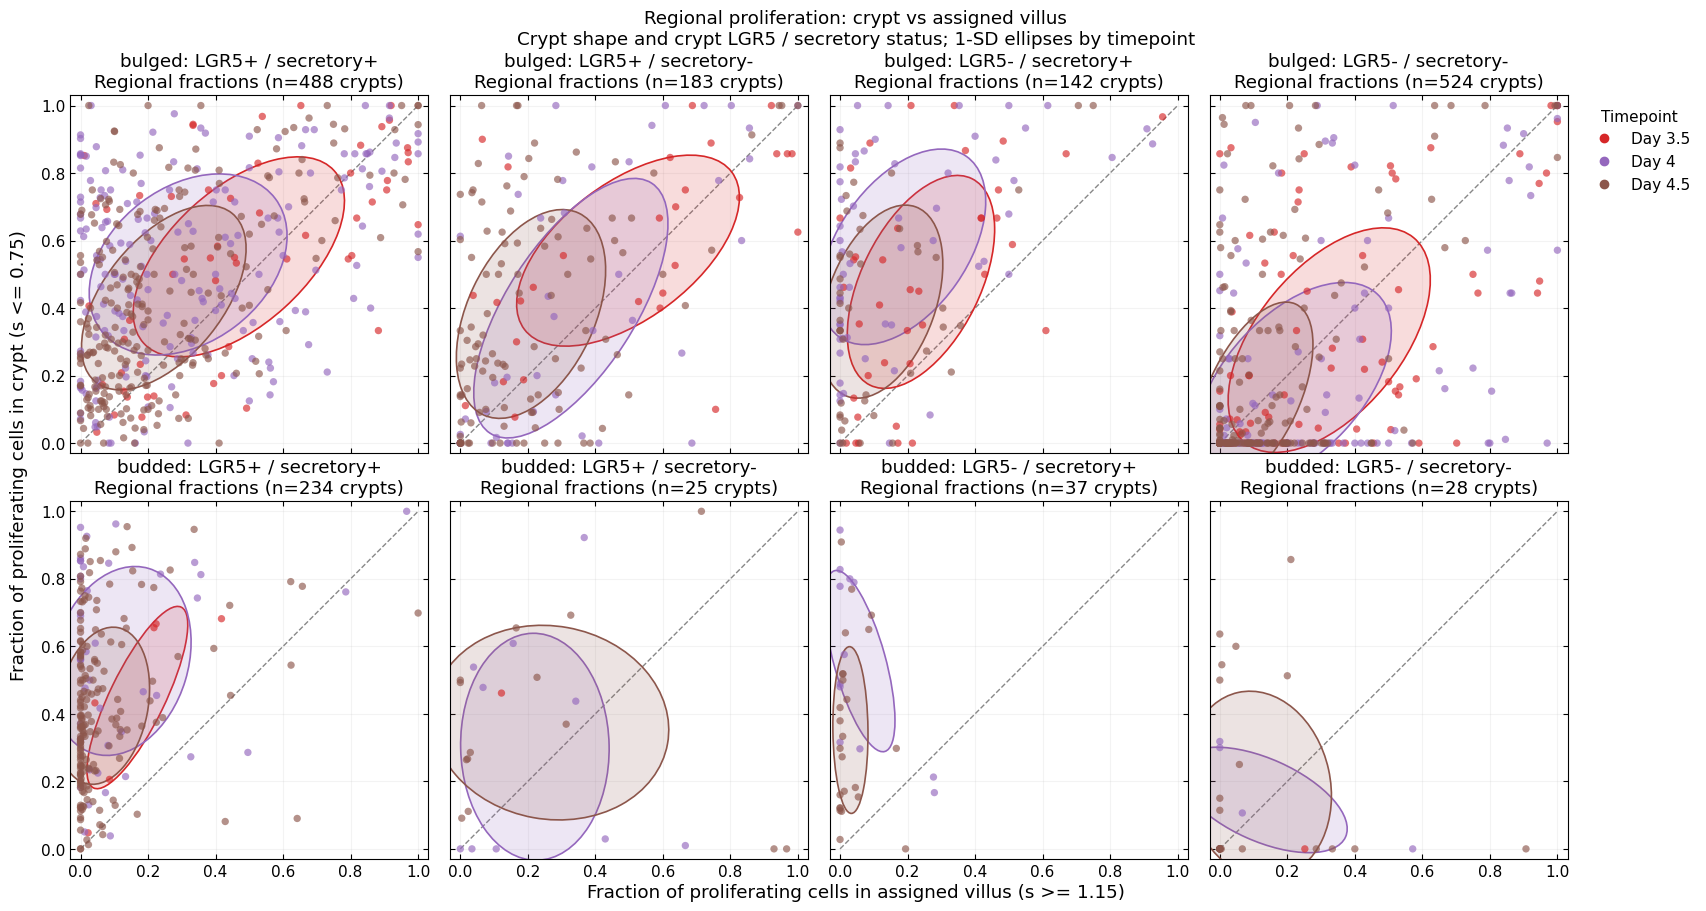

In [8]:
def build_crypt_villus_pairs(table, selected_timepoints, categories):
    identity = ['dataset', 'timepoint', 'label_ID', 'crypt_id']
    metadata = ['crypt_category', 'crypt_has_lgr5', 'crypt_has_secretory']
    metadata += [name for name in ['crypt_category_original', 'budding_index', 'graph_path', 'segmentation_path', 'source_timepoint']
                 if name in table]
    source = table.loc[(table.unit_type == 'crypt') & table.timepoint.isin(selected_timepoints)].copy()
    if source.duplicated(identity + ['region']).any():
        raise ValueError('Duplicate region records for the same crypt.')
    for column in metadata:
        if source.groupby(identity)[column].nunique(dropna=False).gt(1).any():
            raise ValueError(f'Inconsistent crypt metadata: {column}')
    pairs = source[identity + metadata].drop_duplicates(identity)
    metrics = ['n_cells', 'n_proliferating', 'fraction_proliferating']
    for region, suffix in [('Crypt', 'crypt'), ('Villus', 'villus')]:
        part = source.loc[source.region == region, identity + metrics]
        part = part.rename(columns={name: name + '_' + suffix for name in metrics})
        pairs = pairs.merge(part, on=identity, how='left', validate='one_to_one')
    counts = pairs[['n_cells_crypt', 'n_cells_villus']]
    fractions = pairs[['fraction_proliferating_crypt', 'fraction_proliferating_villus']]
    pairs['exclusion_reason'] = np.select([
        ~pairs.crypt_category.isin(categories),
        pairs[['crypt_has_lgr5', 'crypt_has_secretory']].isna().any(axis=1),
        counts.isna().any(axis=1), counts.le(0).any(axis=1),
        ~np.isfinite(fractions).all(axis=1),
        (fractions.lt(0) | fractions.gt(1)).any(axis=1),
    ], ['unclassified crypt', 'missing crypt marker status', 'missing region',
        'empty region', 'nonfinite fraction', 'fraction outside [0, 1]'], default='')
    pairs['included_in_plot'] = pairs.exclusion_reason.eq('')
    return pairs


def plot_crypt_villus_proliferation(pairs, selected_timepoints, categories, colors):
    from matplotlib.lines import Line2D
    from matplotlib.patches import Ellipse
    from matplotlib.colors import to_rgba

    statuses = [(True, True), (True, False), (False, True), (False, False)]
    fig, axes = plt.subplots(len(categories), 4, figsize=(17, 4.5 * len(categories)),
                             squeeze=False, sharex=True, sharey=True, constrained_layout=True)
    summaries = []
    for row, category in enumerate(categories):
        for col, (lgr5, secretory) in enumerate(statuses):
            ax = axes[row, col]
            candidates = pairs.loc[(pairs.crypt_category == category) &
                                   (pairs.crypt_has_lgr5 == lgr5) &
                                   (pairs.crypt_has_secretory == secretory)]
            plotted = candidates.loc[candidates.included_in_plot]
            for tp in selected_timepoints:
                group = plotted.loc[plotted.timepoint == tp]
                candidates_tp = candidates.loc[candidates.timepoint == tp]
                points = group[['fraction_proliferating_villus', 'fraction_proliferating_crypt']].to_numpy(dtype=float)
                ellipse_stats = dict(ellipse_n_std=1.0, mean_villus=np.nan, mean_crypt=np.nan,
                                     cov_villus_villus=np.nan, cov_villus_crypt=np.nan, cov_crypt_crypt=np.nan,
                                     ellipse_status='fewer than three paired crypts')
                if len(points):
                    center = points.mean(axis=0)
                    ellipse_stats.update(mean_villus=float(center[0]), mean_crypt=float(center[1]))
                if len(points) >= 3:
                    covariance = np.cov(points, rowvar=False, ddof=1)
                    ellipse_stats.update(cov_villus_villus=float(covariance[0, 0]),
                                         cov_villus_crypt=float(covariance[0, 1]),
                                         cov_crypt_crypt=float(covariance[1, 1]))
                    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
                    if eigenvalues[0] > np.finfo(float).eps * max(float(eigenvalues[-1]), 1.0):
                        angle = np.degrees(np.arctan2(eigenvectors[1, -1], eigenvectors[0, -1]))
                        ax.add_patch(Ellipse(center, width=2 * np.sqrt(eigenvalues[-1]),
                                             height=2 * np.sqrt(eigenvalues[0]), angle=angle,
                                             facecolor=to_rgba(colors[tp], 0.16), edgecolor=colors[tp],
                                             linewidth=1.2, zorder=1))
                        ellipse_stats['ellipse_status'] = 'drawn'
                    else:
                        ellipse_stats['ellipse_status'] = 'degenerate covariance'
                ax.scatter(group.fraction_proliferating_villus, group.fraction_proliferating_crypt,
                           color=colors[tp], s=28, alpha=0.65, edgecolors='none', zorder=2)
                summaries.append(dict(timepoint=tp, crypt_category=category,
                                      crypt_has_lgr5=lgr5, crypt_has_secretory=secretory,
                                      n_candidate_crypts=len(candidates_tp), n_plotted_crypts=len(group),
                                      n_excluded_crypts=len(candidates_tp) - len(group),
                                      n_organoids=group.label_ID.nunique(), **ellipse_stats))
            ax.plot([0, 1], [0, 1], color='#888888', linestyle='--', linewidth=1, zorder=0.9)
            ax.set_xlim(-0.03, 1.03)
            ax.set_ylim(-0.03, 1.03)
            ax.set_aspect('equal', adjustable='box')
            ax.spines['top'].set_visible(True)
            ax.spines['right'].set_visible(True)
            ax.tick_params(axis='both', which='both', top=True, right=True, direction='in')
            ax.grid(alpha=0.15)
            ax.set_axisbelow(True)
            status_label = f"LGR5{'+' if lgr5 else '-'} / secretory{'+' if secretory else '-'}"
            ax.set_title(f'{category}: {status_label}\nRegional fractions (n={len(plotted)} crypts)')
            if plotted.empty:
                ax.text(0.5, 0.5, 'No paired observations', transform=ax.transAxes, ha='center')
    handles = [Line2D([], [], color=colors[tp], marker='o', linestyle='none',
                      label=tp.replace('day', 'Day ').replace('p', '.')) for tp in selected_timepoints]
    axes[0, -1].legend(handles=handles, title='Timepoint', loc='upper left',
                       bbox_to_anchor=(1.02, 1), frameon=False)
    fig.supxlabel(f'Fraction of proliferating cells in assigned villus (s >= {REGION_VILLUS_MIN:g})')
    fig.supylabel(f'Fraction of proliferating cells in crypt (s <= {REGION_CRYPT_MAX:g})')
    fig.suptitle('Regional proliferation: crypt vs assigned villus\nCrypt shape and crypt LGR5 / secretory status; 1-SD ellipses by timepoint')
    return fig, pd.DataFrame(summaries)


crypt_villus_pairs = build_crypt_villus_pairs(regional_table, CRYPT_COMPARISON_TIMEPOINTS, REGION_CATEGORIES)
fig_crypt_villus, crypt_villus_panel_counts = plot_crypt_villus_proliferation(
    crypt_villus_pairs, CRYPT_COMPARISON_TIMEPOINTS, REGION_CATEGORIES, REGION_TIMEPOINT_COLORS)
print(f'Plotted {int(crypt_villus_pairs.included_in_plot.sum())} paired crypts; '
      f'excluded {int((~crypt_villus_pairs.included_in_plot).sum())}.')
if (~crypt_villus_pairs.included_in_plot).any():
    display(crypt_villus_pairs.loc[~crypt_villus_pairs.included_in_plot].groupby(
        ['timepoint', 'exclusion_reason']).size().rename('n_crypts').to_frame())
plt.show()


In [9]:
if EXPORT:
    REGION_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    regional_table.to_csv(REGION_EXPORT_DIR / 'proliferation_by_crypt_region.csv', index=False)
    regional_crypt_table.drop(columns=['region', 'n_cells', 'n_proliferating',
                                      'fraction_proliferating', 'n_ta', 'fraction_ta', 'cell_node_ids']).to_csv(
        REGION_EXPORT_DIR / 'crypt_classification_and_marker_status.csv', index=False)
    crypt_status_fraction_table.to_csv(REGION_EXPORT_DIR / 'crypt_lgr5_secretory_fractions.csv', index=False)
    fig_crypt_status.savefig(REGION_EXPORT_DIR / 'crypt_lgr5_secretory_fractions.svg', bbox_inches='tight')
    fig_crypt_status.savefig(REGION_EXPORT_DIR / 'crypt_lgr5_secretory_fractions.png', dpi=180, bbox_inches='tight')
    regional_plot_summary.to_csv(REGION_EXPORT_DIR / 'regional_proliferation_plot_statistics.csv', index=False)
    crypt_villus_pairs.to_csv(REGION_EXPORT_DIR / 'crypt_villus_proliferation_pairs.csv', index=False)
    crypt_villus_panel_counts.to_csv(REGION_EXPORT_DIR / 'crypt_villus_proliferation_panel_counts.csv', index=False)
    for extension in ['svg', 'png']:
        fig_crypt_villus.savefig(REGION_EXPORT_DIR / f'crypt_villus_proliferation_scatter.{extension}',
                                dpi=180, bbox_inches='tight')
    regional_audit.to_csv(REGION_EXPORT_DIR / 'excluded_or_invalid_files.csv', index=False)
    settings = dict(dataset=DATASET, timepoints=CRYPT_COMPARISON_TIMEPOINTS, min_cells=MIN_CELLS,
                    source_timepoints=REGION_SOURCE_TIMEPOINTS, timepoint_aliases=TIMEPOINT_ALIASES,
                    regional_violin_timepoints=REGION_TIMEPOINTS, timepoint_colors=REGION_TIMEPOINT_COLORS,
                    graph_dir=str(GRAPH_DIR), segmentation_dir=str(REGION_SEGMENTATION_DIR),
                    marker_field='markers_bin', additional_exclusivity=False,
                    ta_rule='Cyclin A or D positive; no other measured marker positive',
                    s_star=REGION_S_STAR, bi_interval=REGION_BI_INTERVAL,
                    bi_formula='(C(s_star)-C(1))/max(C(s<=1))',
                    crypt_s_max_inclusive=REGION_CRYPT_MAX, villus_s_min_inclusive=REGION_VILLUS_MIN,
                    cell_assignment='minimum normalized distance; ties use first saved crypt',
                    crypt_marker_status_region='assigned Crypt cells only',
                    crypt_villus_scatter=dict(x='fraction_proliferating_villus',
                        y='fraction_proliferating_crypt', unit='one paired crypt',
                        color='timepoint', zero_fractions='included',
                        ellipse_n_std=1.0, ellipse_covariance_ddof=1, ellipse_coordinates='linear fractions',
                        invalid_pairs='excluded with reason in paired table'),
                    no_crypt_reference='whole organoid with zero retained graph crypts; unsplit',
                    empty_region_fraction='NaN', categories=REGION_CATEGORIES,
                    category_merge={'weakly budded': 'budded', 'fully budded': 'budded'},
                    violin_sides={'left': 'proliferating', 'right': 'TA'},
                    violin_summary='solid median, dashed 25th and 75th percentiles',
                    violin_density='Gaussian KDE, Scott bandwidth, 100 points, sample-extrema support',
                    violin_normalization='equal maximum width per half; constant groups shown as lines',
                    plots='per-unit split violins; no pooling of fractions; marker strata at separate x positions')
    (REGION_EXPORT_DIR / 'analysis_settings.json').write_text(json.dumps(settings, indent=2) + '\n')
    for name, fig in regional_figures.items():
        fig.savefig(REGION_EXPORT_DIR / f'{name}.png', dpi=180, bbox_inches='tight')
        fig.savefig(REGION_EXPORT_DIR / f'{name}.svg', bbox_inches='tight')
    print(f'Exported regional analysis to {REGION_EXPORT_DIR}')


Exported regional analysis to /home/fmoller/Projects/LearningOrganoids/OrganoGraph/exports/proliferation_symmetry_breaking/20250929/crypt_regions_day3p5_day4_day4p5
